In [36]:
'''
new sobel ratio lets go
'''

'\nnew sobel ratio lets go\n'

In [3]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



import precision_recall as pr


# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os


import precision_recall as pr


# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os
import implantation_functions as imp
import get_postage_stamps as gpsf
import fitting

from scipy.ndimage import sobel
from scipy.signal import find_peaks
import importlib

plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [18]:
def get_stamp_from_hdul(hdul, index, direcname, df, norm=True, quad=None):
    """
    returns a 20x20 numpy array of brightnesses centered around the detection
    located at index of dataframe df
    note that the filepath to the science images is hardcoded currently
    norm=True has the image normalized (not the stamp, the entire image)
    norm=False has it in terms of counts
    """
    # fname = df.loc[index]["filename"] + "fits.fz"
    row = int(df.loc[index]["row_from_nn"]) + 10
    col = int(df.loc[index]["col_from_nn"]) + 10
    if quad==None:
        quad = int(df.loc[index]["quad"])
    file1_array = hdul[quad].data
    if norm:
        normalized = (file1_array - np.min(file1_array)) / (
            np.max(file1_array) - np.min(file1_array)
        )  # norm
        stamp = normalized[row - 10 : row + 10, col - 10 : col + 10]
        # plt.imshow(stamp)
        # plt.colorbar()
        background = get_image_background(normalized)
        return stamp, background
        
    stamp = file1_array[row - 10 : row + 10, col - 10 : col + 10]
    # plt.imshow(stamp)
    # plt.colorbar()
    background = rff.get_image_background(file1_array)
    return stamp, background

In [23]:
def add_sobel_ratio_fast(df, direcname='1020'):
    """
    returns the dataframe with a new column of sobel ratios
    see get_sobel_ratio(stamp)
    """
    sobels = {}
    sobels_x = {}
    sobels_y = {}
    # i=0
    for filename, group in df.groupby('filename'):     
        fpath = (
            "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
            + direcname
            + "_minus_extras/"
        )
        path = fpath + filename+'fits.fz'
        with fits.open(path) as hdul:
            for idx in group.index:
                # quad = int(df.loc[idx]["quad"])
                
                stamp, bg = get_stamp_from_hdul(hdul, idx, direcname, df, norm=False)
                sobel, x, y = rff.get_sobel_ratio(stamp-bg)
                # print(sobel)
                # print(np.shape(x))
                # print(np.shape(y))
                sobels[idx] = sobel
                sobels_x[idx] = x
                sobels_y[idx] = y
                # i+=1
        print(sobels)
        
        break
    df["sobel_ratio"] = df.index.map(sobels)
    df["sobels_x"] = df.index.map(sobels_x)
    df["sobels_y"] = df.index.map(sobels_y)
    return df

In [11]:
df = pd.read_csv(
    "/lustre/lrspec/ZTF_data/efficiency_testing/df_snr_4")

In [24]:
add_sobel_ratio_fast(df)

KeyboardInterrupt: 

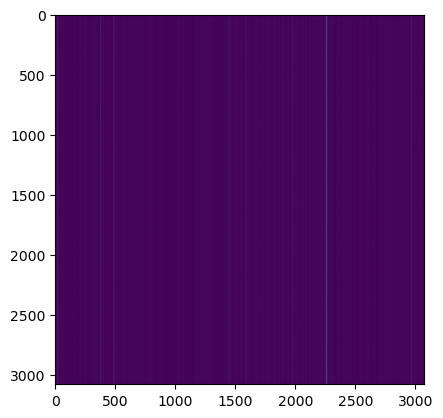

724280


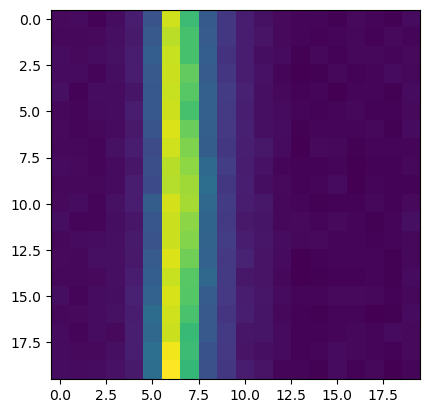

{724280: 19.544765}
724281


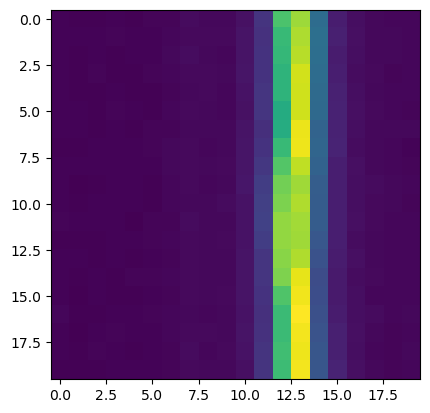

{724280: 19.544765, 724281: 18.310057}
724282


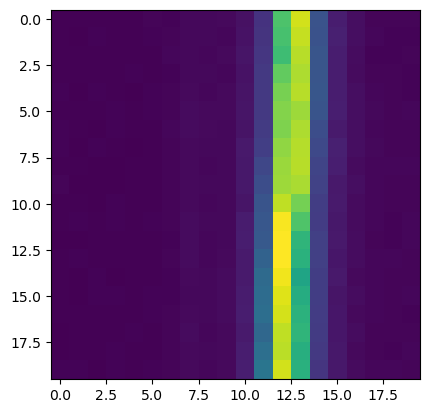

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558}
724283


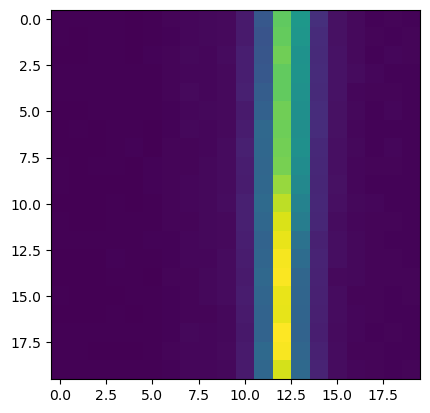

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656}
724284


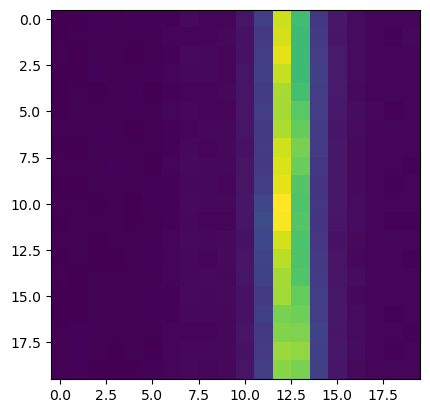

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299}
724285


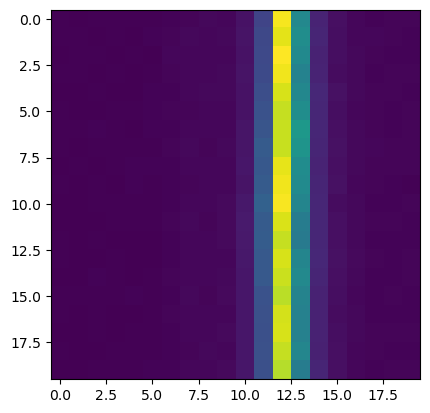

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703}
724286


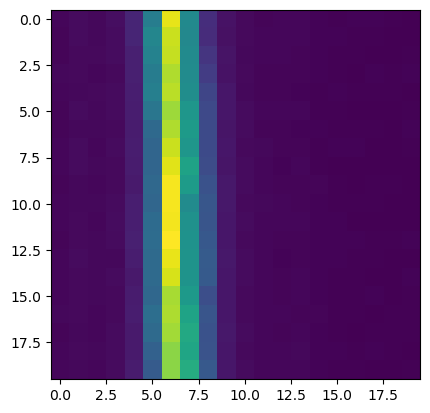

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074}
724287


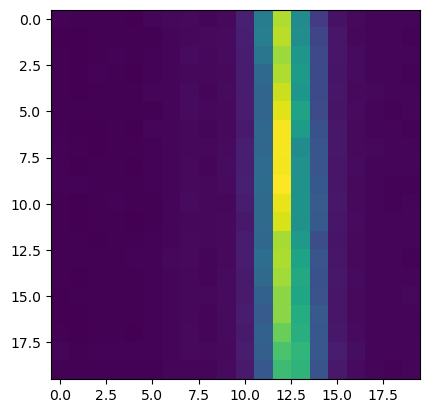

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074}
724288


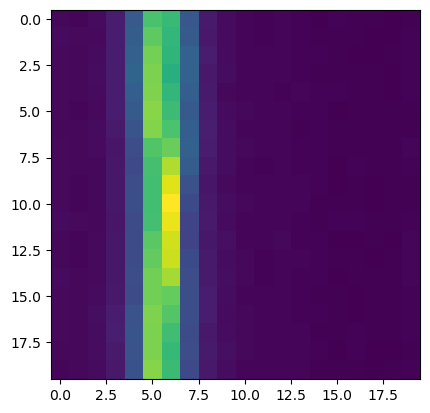

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846}
724289


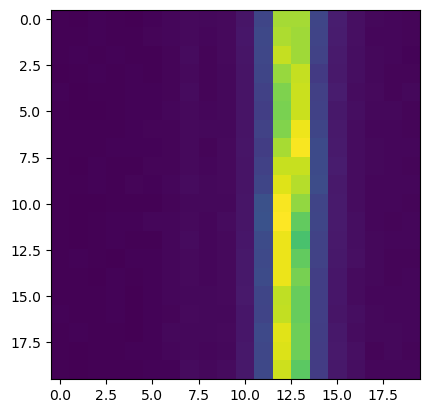

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105}
724290


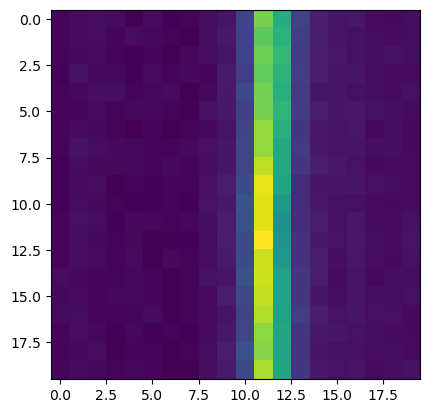

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291}
724291


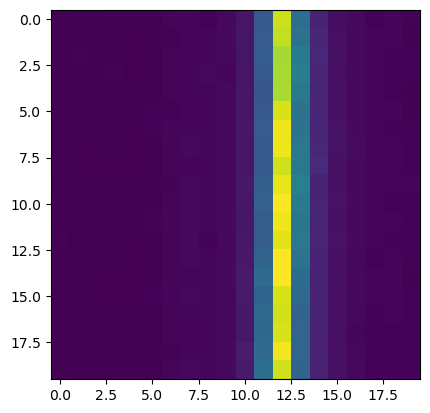

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326}
724292


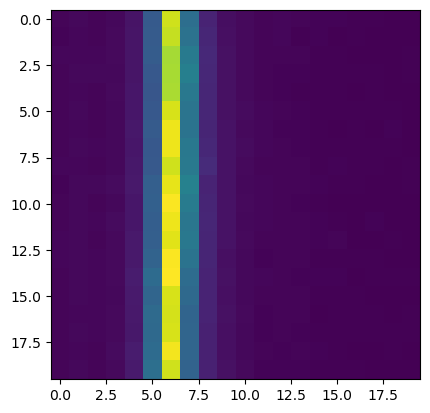

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326}
724293


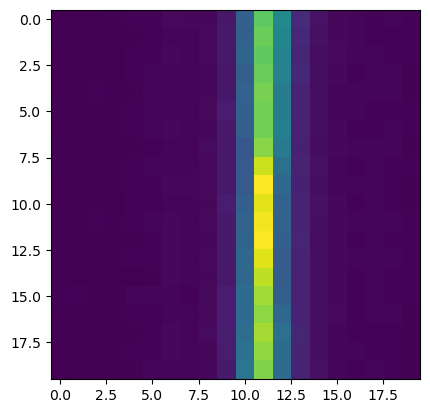

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303}
724294


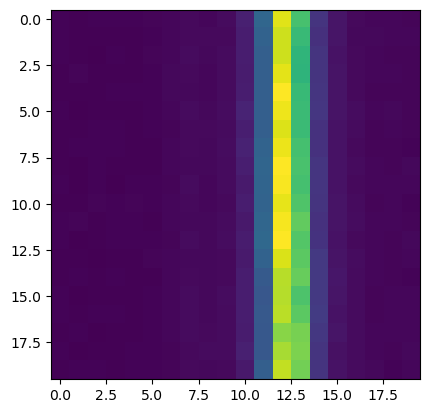

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849}
724295


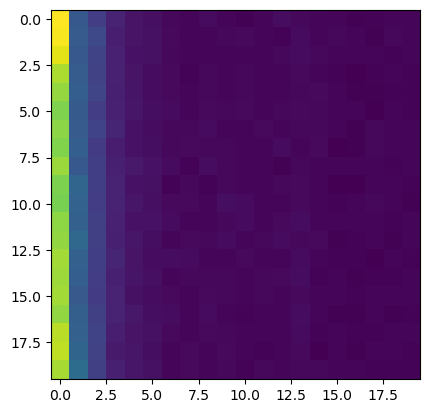

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252}
724296


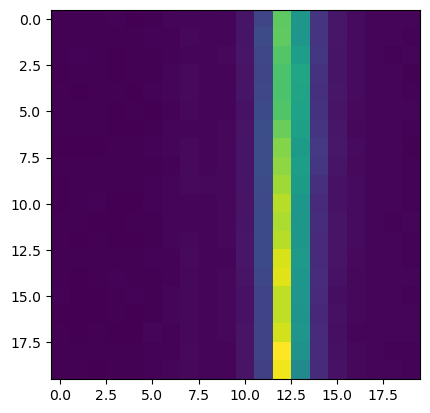

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077}
724297


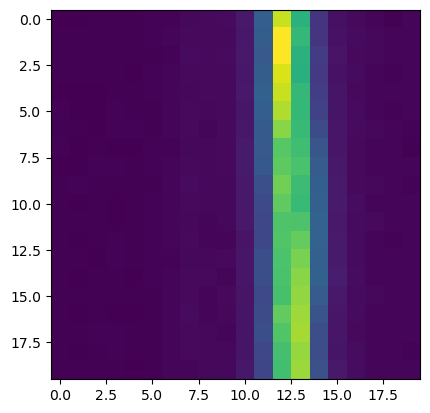

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787}
724298


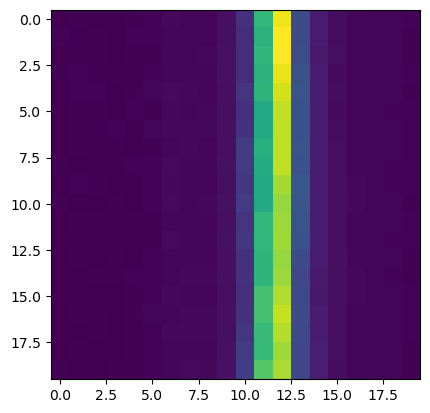

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787, 724298: 17.856882}
724299


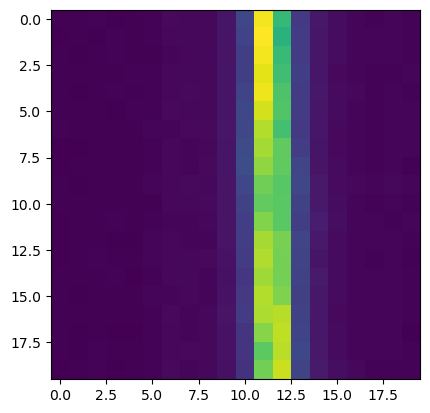

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787, 724298: 17.856882, 724299: 15.111943}
724300


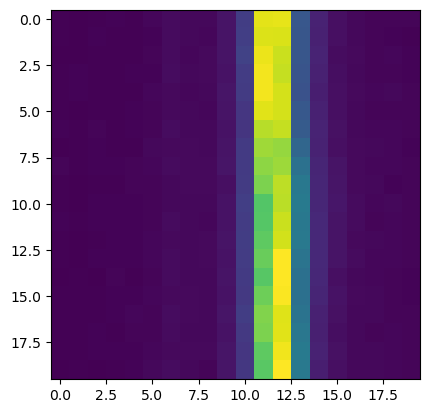

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787, 724298: 17.856882, 724299: 15.111943, 724300: 17.709858}
724301


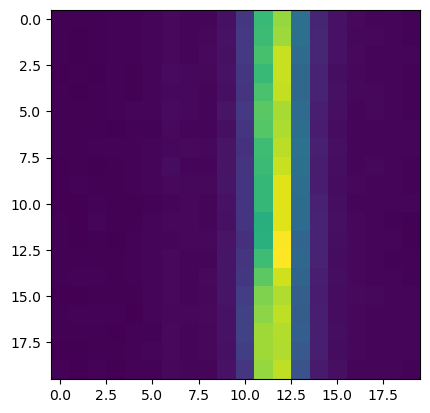

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787, 724298: 17.856882, 724299: 15.111943, 724300: 17.709858, 724301: 17.657001}
724302


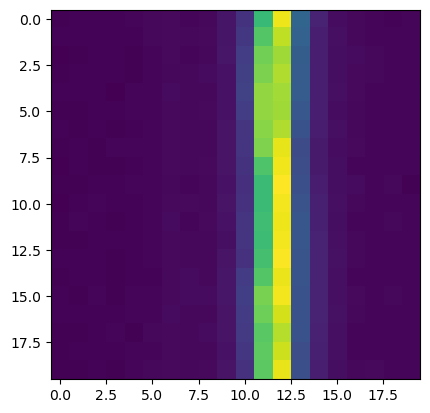

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787, 724298: 17.856882, 724299: 15.111943, 724300: 17.709858, 724301: 17.657001, 724302: 15.797143}
724303


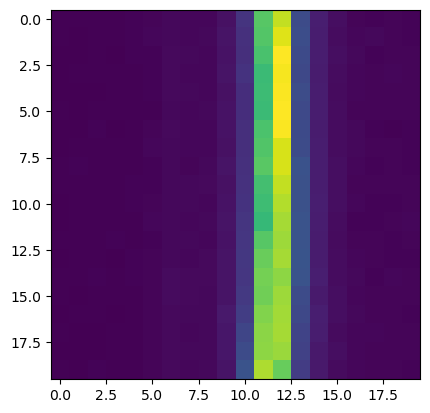

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787, 724298: 17.856882, 724299: 15.111943, 724300: 17.709858, 724301: 17.657001, 724302: 15.797143, 724303: 16.239208}
724304


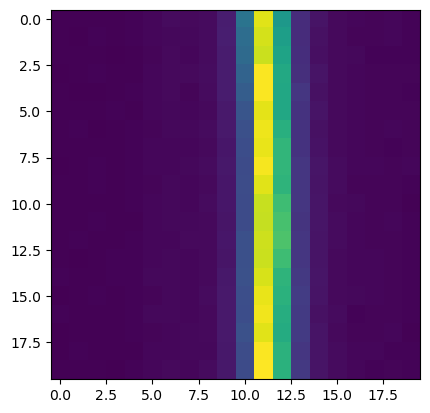

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787, 724298: 17.856882, 724299: 15.111943, 724300: 17.709858, 724301: 17.657001, 724302: 15.797143, 724303: 16.239208, 724304: 25.79778}
724305


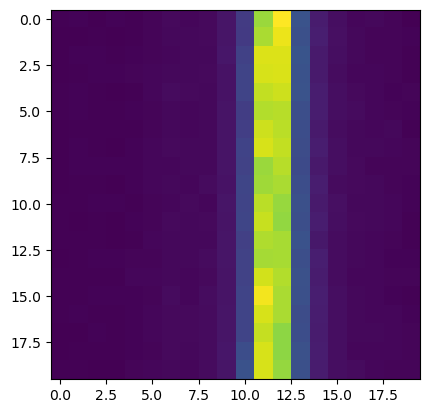

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787, 724298: 17.856882, 724299: 15.111943, 724300: 17.709858, 724301: 17.657001, 724302: 15.797143, 724303: 16.239208, 724304: 25.79778, 724305: 14.71243}
724306


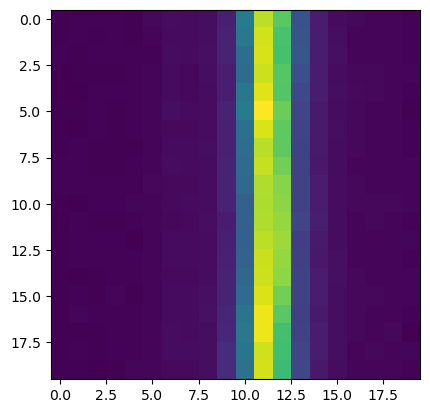

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787, 724298: 17.856882, 724299: 15.111943, 724300: 17.709858, 724301: 17.657001, 724302: 15.797143, 724303: 16.239208, 724304: 25.79778, 724305: 14.71243, 724306: 14.639309}
724307


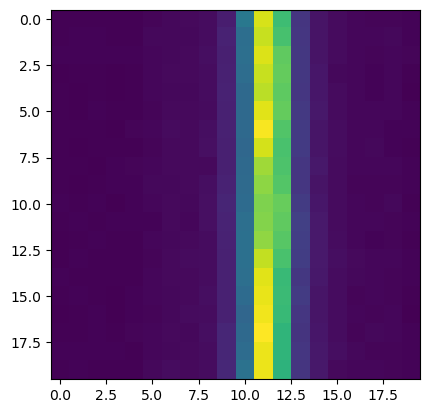

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787, 724298: 17.856882, 724299: 15.111943, 724300: 17.709858, 724301: 17.657001, 724302: 15.797143, 724303: 16.239208, 724304: 25.79778, 724305: 14.71243, 724306: 14.639309, 724307: 20.080614}
724308


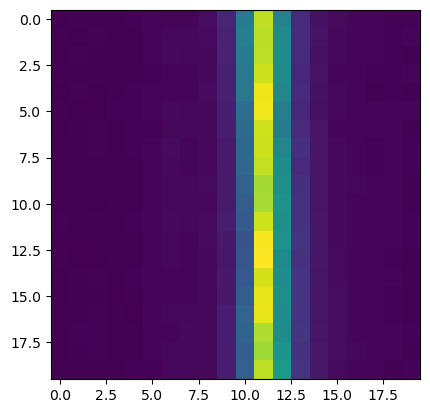

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787, 724298: 17.856882, 724299: 15.111943, 724300: 17.709858, 724301: 17.657001, 724302: 15.797143, 724303: 16.239208, 724304: 25.79778, 724305: 14.71243, 724306: 14.639309, 724307: 20.080614, 724308: 17.125189}
724309


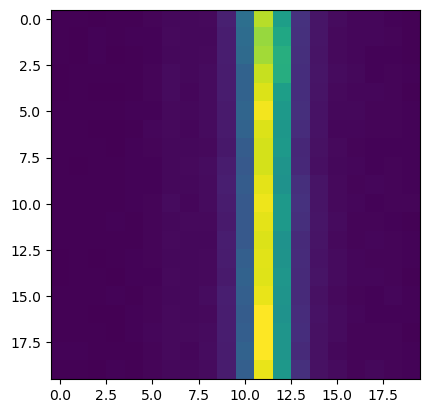

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787, 724298: 17.856882, 724299: 15.111943, 724300: 17.709858, 724301: 17.657001, 724302: 15.797143, 724303: 16.239208, 724304: 25.79778, 724305: 14.71243, 724306: 14.639309, 724307: 20.080614, 724308: 17.125189, 724309: 30.02799}
724310


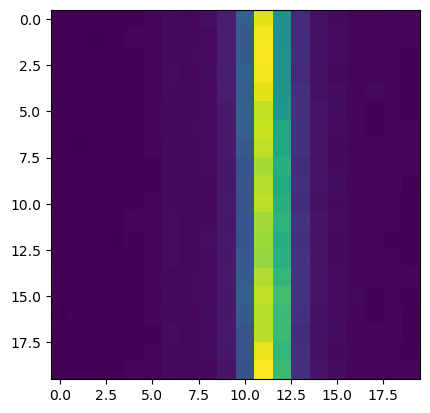

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787, 724298: 17.856882, 724299: 15.111943, 724300: 17.709858, 724301: 17.657001, 724302: 15.797143, 724303: 16.239208, 724304: 25.79778, 724305: 14.71243, 724306: 14.639309, 724307: 20.080614, 724308: 17.125189, 724309: 30.02799, 724310: 17.316595}
724311


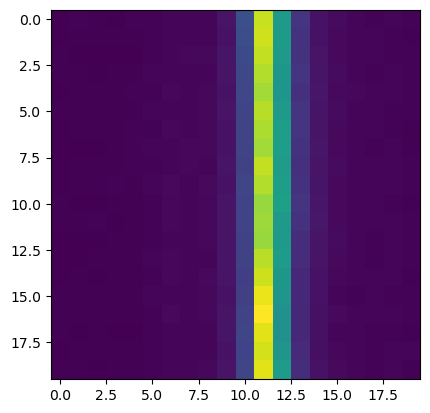

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787, 724298: 17.856882, 724299: 15.111943, 724300: 17.709858, 724301: 17.657001, 724302: 15.797143, 724303: 16.239208, 724304: 25.79778, 724305: 14.71243, 724306: 14.639309, 724307: 20.080614, 724308: 17.125189, 724309: 30.02799, 724310: 17.316595, 724311: 24.490456}
724312


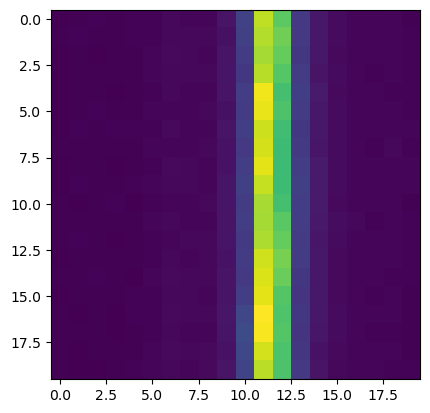

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787, 724298: 17.856882, 724299: 15.111943, 724300: 17.709858, 724301: 17.657001, 724302: 15.797143, 724303: 16.239208, 724304: 25.79778, 724305: 14.71243, 724306: 14.639309, 724307: 20.080614, 724308: 17.125189, 724309: 30.02799, 724310: 17.316595, 724311: 24.490456, 724312: 21.452646}
724313


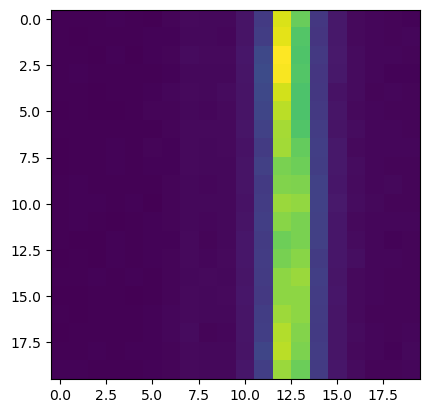

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787, 724298: 17.856882, 724299: 15.111943, 724300: 17.709858, 724301: 17.657001, 724302: 15.797143, 724303: 16.239208, 724304: 25.79778, 724305: 14.71243, 724306: 14.639309, 724307: 20.080614, 724308: 17.125189, 724309: 30.02799, 724310: 17.316595, 724311: 24.490456, 724312: 21.452646, 724313: 20.543299}
724314


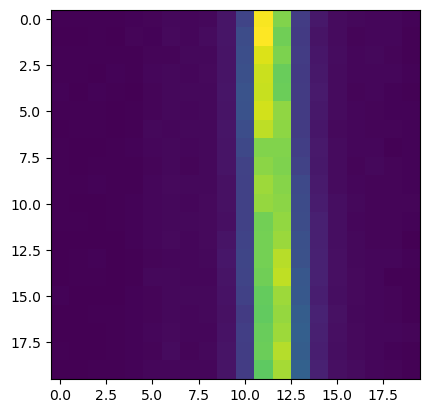

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787, 724298: 17.856882, 724299: 15.111943, 724300: 17.709858, 724301: 17.657001, 724302: 15.797143, 724303: 16.239208, 724304: 25.79778, 724305: 14.71243, 724306: 14.639309, 724307: 20.080614, 724308: 17.125189, 724309: 30.02799, 724310: 17.316595, 724311: 24.490456, 724312: 21.452646, 724313: 20.543299, 724314: 26.836088}
724315


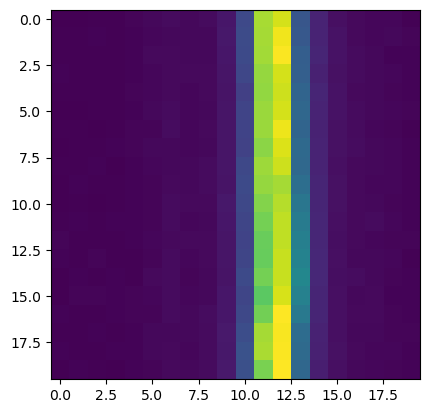

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787, 724298: 17.856882, 724299: 15.111943, 724300: 17.709858, 724301: 17.657001, 724302: 15.797143, 724303: 16.239208, 724304: 25.79778, 724305: 14.71243, 724306: 14.639309, 724307: 20.080614, 724308: 17.125189, 724309: 30.02799, 724310: 17.316595, 724311: 24.490456, 724312: 21.452646, 724313: 20.543299, 724314: 26.836088, 724315: 10.258498}
724316


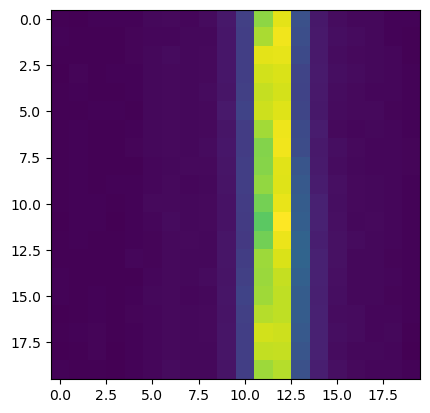

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787, 724298: 17.856882, 724299: 15.111943, 724300: 17.709858, 724301: 17.657001, 724302: 15.797143, 724303: 16.239208, 724304: 25.79778, 724305: 14.71243, 724306: 14.639309, 724307: 20.080614, 724308: 17.125189, 724309: 30.02799, 724310: 17.316595, 724311: 24.490456, 724312: 21.452646, 724313: 20.543299, 724314: 26.836088, 724315: 10.258498, 724316: 13.350062}
724317


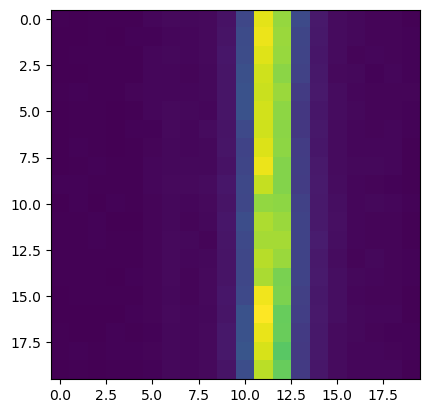

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787, 724298: 17.856882, 724299: 15.111943, 724300: 17.709858, 724301: 17.657001, 724302: 15.797143, 724303: 16.239208, 724304: 25.79778, 724305: 14.71243, 724306: 14.639309, 724307: 20.080614, 724308: 17.125189, 724309: 30.02799, 724310: 17.316595, 724311: 24.490456, 724312: 21.452646, 724313: 20.543299, 724314: 26.836088, 724315: 10.258498, 724316: 13.350062, 724317: 14.135898}
724318


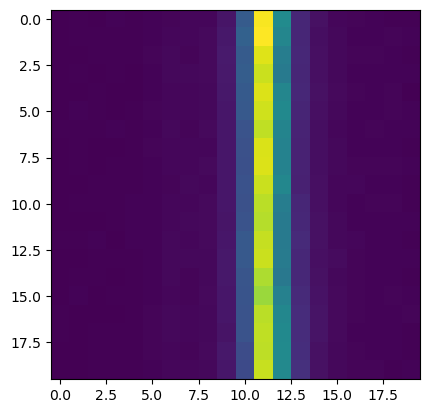

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787, 724298: 17.856882, 724299: 15.111943, 724300: 17.709858, 724301: 17.657001, 724302: 15.797143, 724303: 16.239208, 724304: 25.79778, 724305: 14.71243, 724306: 14.639309, 724307: 20.080614, 724308: 17.125189, 724309: 30.02799, 724310: 17.316595, 724311: 24.490456, 724312: 21.452646, 724313: 20.543299, 724314: 26.836088, 724315: 10.258498, 724316: 13.350062, 724317: 14.135898, 724318: 24.04226}
724319


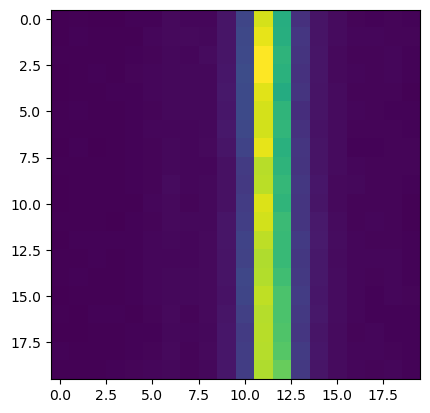

{724280: 19.544765, 724281: 18.310057, 724282: 16.658558, 724283: 20.458656, 724284: 20.543299, 724285: 30.720703, 724286: 21.073074, 724287: 21.073074, 724288: 10.655846, 724289: 14.874105, 724290: 14.951291, 724291: 17.896326, 724292: 17.896326, 724293: 13.066303, 724294: 19.028849, 724295: 0.27703252, 724296: 20.203077, 724297: 19.915787, 724298: 17.856882, 724299: 15.111943, 724300: 17.709858, 724301: 17.657001, 724302: 15.797143, 724303: 16.239208, 724304: 25.79778, 724305: 14.71243, 724306: 14.639309, 724307: 20.080614, 724308: 17.125189, 724309: 30.02799, 724310: 17.316595, 724311: 24.490456, 724312: 21.452646, 724313: 20.543299, 724314: 26.836088, 724315: 10.258498, 724316: 13.350062, 724317: 14.135898, 724318: 24.04226, 724319: 21.658455}
724320


KeyboardInterrupt: 

In [27]:
sobels = {}
sobels_x = {}
sobels_y = {}
direcname='1020'
# i=0
for filename, group in df.groupby('filename'):     
    fpath = (
        "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
        + '1020'
        + "_minus_extras/"
    )
    path = fpath + filename+'fits.fz'
    with fits.open(path) as hdul:
        plt.imshow(hdul[1].data)
        plt.show()
        for idx in group.index:
            # quad = int(df.loc[idx]["quad"])
            print(idx)
            stamp, bg = get_stamp_from_hdul(hdul, idx, direcname, df, norm=False)
            plt.imshow(stamp)
            plt.show()
            sobel, x, y = rff.get_sobel_ratio(stamp-bg)
            # print(sobel)
            # print(np.shape(x))
            # print(np.shape(y))
            sobels[idx] = sobel
            print(sobels)
            sobels_x[idx] = x
            sobels_y[idx] = y
            # i+=1
    print(sobels)
    
    break

In [28]:
sobels_y

{724280: array([[-1.56313782e+01,  1.22970581e+00,  2.78375854e+01,
          2.11865997e+01,  1.66545868e+01,  8.23135376e+00,
         -1.25359802e+01,  1.25254517e+01,  2.41745300e+01,
          1.09389038e+01,  1.35470123e+01,  1.17373047e+01,
          7.44409180e+00,  4.27230835e-01, -5.83499146e+00,
         -4.03794861e+00, -6.95903015e+00,  5.07841492e+00,
          1.69925995e+01, -7.07879639e+00],
        [ 1.14614105e+01,  1.74174805e+01,  4.02705536e+01,
          3.18846893e+01,  3.83812714e+01,  5.34996643e+01,
          2.84757385e+01,  3.14174805e+01,  2.52002869e+01,
         -7.44656372e+00, -1.14907532e+01, -7.52592468e+00,
         -5.42771912e+00, -4.04780579e+00, -5.60241699e-01,
         -2.34109497e+00, -3.87031555e+00,  1.26337738e+01,
          1.73078003e+01, -6.07223511e-01],
        [ 1.58048706e+01,  6.70211792e-01, -2.27506561e+01,
         -1.85126343e+01, -8.16925049e-01,  1.71812439e+01,
          6.63558350e+01,  8.49197693e+01,  2.85520935e+01,
    

In [2]:
df = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/df_snr_sobel")

(0.0, 5.0)

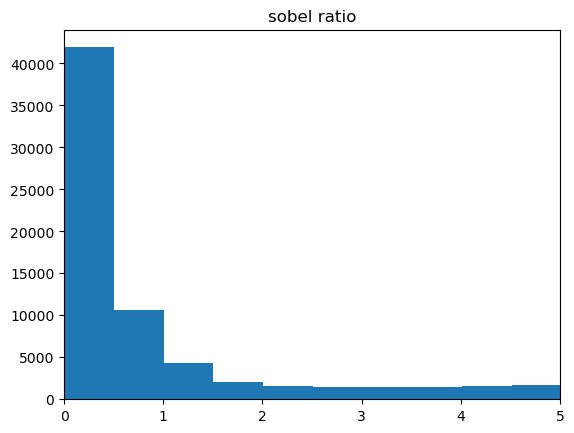

In [27]:
plt.hist(df['sobel_ratio'], bins=180)
plt.title("sobel ratio")
plt.xlim(0,5)

(0.0, 5.0)

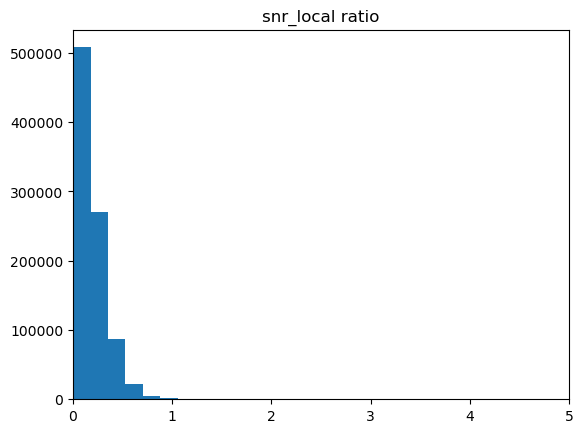

In [20]:
plt.hist(df['snr_local'], bins=80)
plt.title("snr_local ratio")
plt.xlim(0,5)

In [26]:
np.sum(df_high['sobel_ratio']<1)

2348

In [12]:
df['quadrant']=df['quad']

In [68]:
df_high = df2[df2['snr_local']>.5]

In [62]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

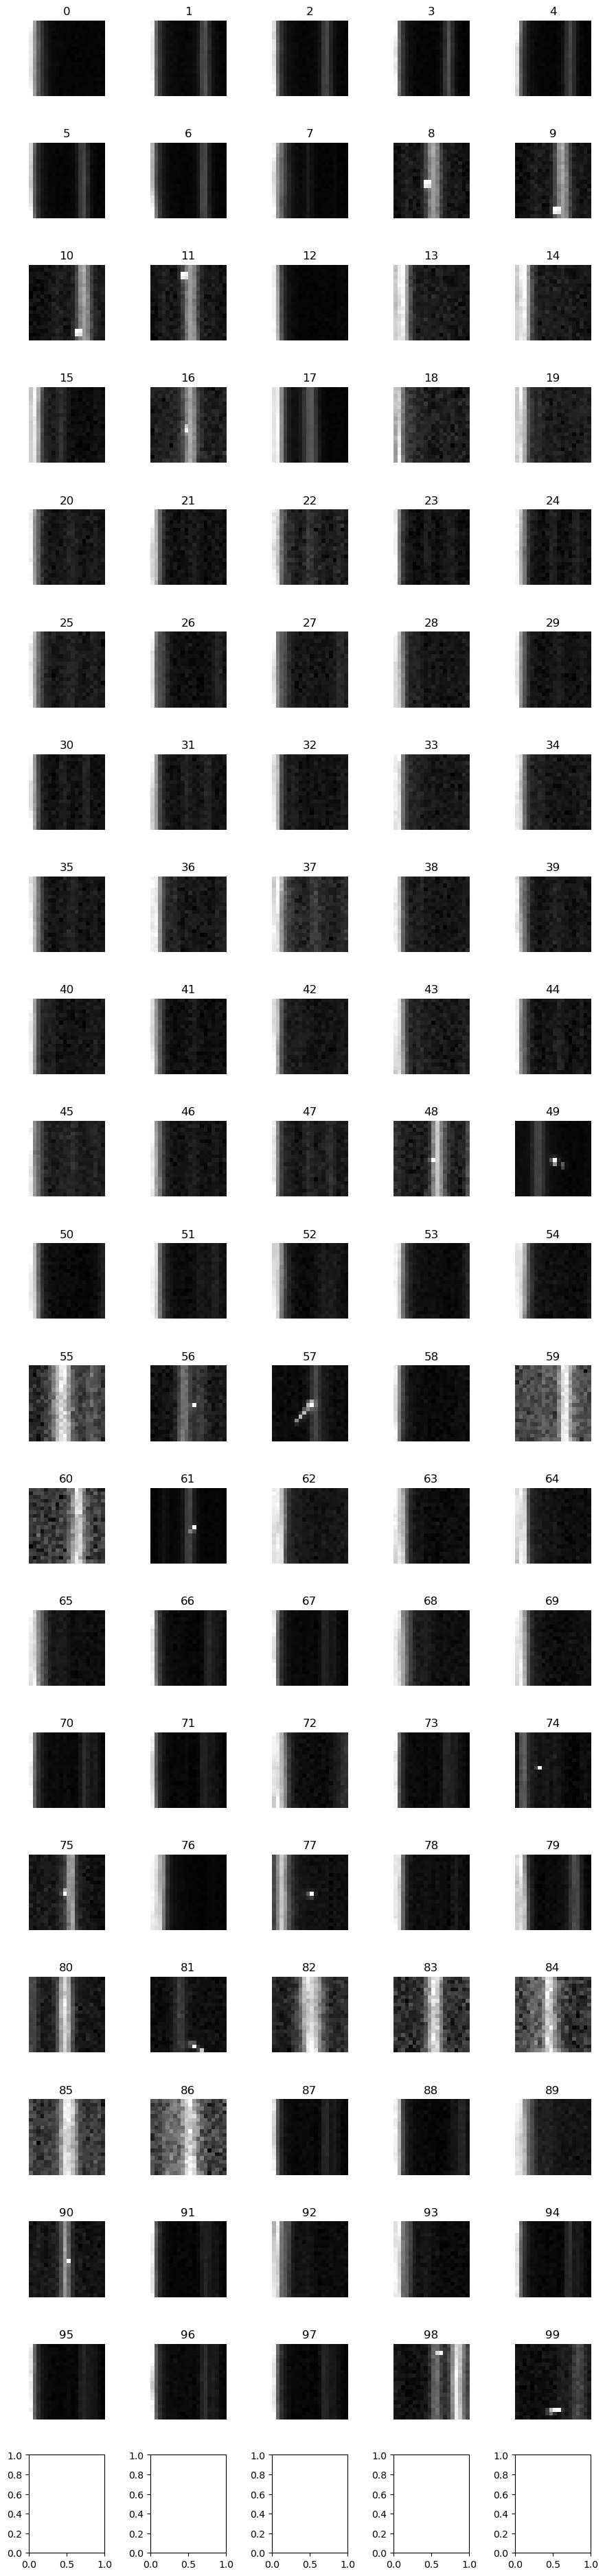

In [90]:
rff.inspect_df_with_quadrant(df_high[df_high['sobel_ratio']<5][:100], direcname='1020')

In [32]:
for i, row in df_high[df_high['sobel_ratio']<1][:100].iterrows():
    print(i)
    print(np.max(np.array(row['sobels_x'])/np.array(row['sobels_y'])))

164


TypeError: ufunc 'divide' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

In [51]:
row['sobels_x'][1:-1]

'[-3.94117090e+03 -6.17864600e+03 -2.98530591e+03 -1.06495874e+03\n  -4.57926880e+02 -1.64115051e+02 -8.16959991e+01 -2.85756378e+01\n   1.53979492e+00 -3.53541412e+01  2.72521667e+01  2.81646729e-01\n  -2.01252747e+01  7.90100098e+00 -1.92276154e+01 -6.30888367e+00\n   6.64431763e+00  1.26940155e+01  6.20259094e+00 -6.73175049e+00]\n [-3.87133594e+03 -5.99556787e+03 -2.85164746e+03 -1.08509363e+03\n  -4.98546021e+02 -1.67383713e+02 -7.36092224e+01 -2.88439484e+01\n  -6.63757324e+00 -2.24950867e+01  9.90760803e+00 -1.84147339e+01\n  -7.33074951e+00 -5.10420227e+00 -1.53737335e+01  1.93408813e+01\n   1.54376984e+01 -1.05001831e+00  1.50486755e+00  6.98226929e+00]\n [-3.67858008e+03 -5.65593359e+03 -2.70836377e+03 -1.09332324e+03\n  -5.01116028e+02 -1.72737061e+02 -7.32251740e+01 -4.66868134e+01\n  -1.45527954e+01  5.38307190e+00 -5.32675171e+00 -2.29851074e+01\n   5.44009399e+00 -8.38442993e+00 -1.74833984e+01  2.22098083e+01\n   1.36083832e+01 -1.11131744e+01 -1.66239929e+00  2.3085327

In [50]:
row['sobels_x'][1:-1].split('[')

['',
 '-3.94117090e+03 -6.17864600e+03 -2.98530591e+03 -1.06495874e+03\n  -4.57926880e+02 -1.64115051e+02 -8.16959991e+01 -2.85756378e+01\n   1.53979492e+00 -3.53541412e+01  2.72521667e+01  2.81646729e-01\n  -2.01252747e+01  7.90100098e+00 -1.92276154e+01 -6.30888367e+00\n   6.64431763e+00  1.26940155e+01  6.20259094e+00 -6.73175049e+00]\n ',
 '-3.87133594e+03 -5.99556787e+03 -2.85164746e+03 -1.08509363e+03\n  -4.98546021e+02 -1.67383713e+02 -7.36092224e+01 -2.88439484e+01\n  -6.63757324e+00 -2.24950867e+01  9.90760803e+00 -1.84147339e+01\n  -7.33074951e+00 -5.10420227e+00 -1.53737335e+01  1.93408813e+01\n   1.54376984e+01 -1.05001831e+00  1.50486755e+00  6.98226929e+00]\n ',
 '-3.67858008e+03 -5.65593359e+03 -2.70836377e+03 -1.09332324e+03\n  -5.01116028e+02 -1.72737061e+02 -7.32251740e+01 -4.66868134e+01\n  -1.45527954e+01  5.38307190e+00 -5.32675171e+00 -2.29851074e+01\n   5.44009399e+00 -8.38442993e+00 -1.74833984e+01  2.22098083e+01\n   1.36083832e+01 -1.11131744e+01 -1.66239929e+

In [45]:
row['sobels_x']

'[[-3.94117090e+03 -6.17864600e+03 -2.98530591e+03 -1.06495874e+03\n  -4.57926880e+02 -1.64115051e+02 -8.16959991e+01 -2.85756378e+01\n   1.53979492e+00 -3.53541412e+01  2.72521667e+01  2.81646729e-01\n  -2.01252747e+01  7.90100098e+00 -1.92276154e+01 -6.30888367e+00\n   6.64431763e+00  1.26940155e+01  6.20259094e+00 -6.73175049e+00]\n [-3.87133594e+03 -5.99556787e+03 -2.85164746e+03 -1.08509363e+03\n  -4.98546021e+02 -1.67383713e+02 -7.36092224e+01 -2.88439484e+01\n  -6.63757324e+00 -2.24950867e+01  9.90760803e+00 -1.84147339e+01\n  -7.33074951e+00 -5.10420227e+00 -1.53737335e+01  1.93408813e+01\n   1.54376984e+01 -1.05001831e+00  1.50486755e+00  6.98226929e+00]\n [-3.67858008e+03 -5.65593359e+03 -2.70836377e+03 -1.09332324e+03\n  -5.01116028e+02 -1.72737061e+02 -7.32251740e+01 -4.66868134e+01\n  -1.45527954e+01  5.38307190e+00 -5.32675171e+00 -2.29851074e+01\n   5.44009399e+00 -8.38442993e+00 -1.74833984e+01  2.22098083e+01\n   1.36083832e+01 -1.11131744e+01 -1.66239929e+00  2.308532

In [55]:
np.max(sobels_to_array(row['sobels_x'])/sobels_to_array(row['sobels_y']))

833.294077831609

In [18]:
def sobels_to_array(original):
    # array = np.zeros((20,20))
    cleaned = original[1:-1]
    
    # Split into rows
    rows = []
    current_row = []
    
    # Split by brackets to identify rows
    parts = cleaned.split('[')
    for part in parts:
        if not part.strip():
            continue
        
        # Remove closing bracket and split by whitespace
        part = part.replace(']', '')
        values = part.split()
        
        for val in values:
            val = val.strip()
            if val and val != ',':
                try:
                    current_row.append(float(val))
                except ValueError:
                    continue
        
        if len(current_row) == 20:
            rows.append(current_row)
            current_row = []
    
    return np.array(rows)
        
# row['sobels_x'].split()

In [57]:
def add_sobel_max(df):
    df['sobel_max'] = np.zeros(len(df))
    for i, row in df.iterrows():
        df['sobel_max'].loc[i] = np.max(sobels_to_array(row['sobels_x'])/sobels_to_array(row['sobels_y']))
    return df

In [59]:
df2 = add_sobel_max(df)

/tmp/ipykernel_57915/1397574270.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['sobel_max'].loc[i] = np.max(sobels_to_array(row['sobels_x'])/sobels_to_array(row['sobels_y']))
/tmp/ipykernel_57915/1397574270.py:4: RuntimeWarning: divide by zero encountered in divide
  df['sobel_max'].loc[i] = np.max(sobels_to_array(row['sobels_x'])/sobels_to_array(row['sobels_y']))


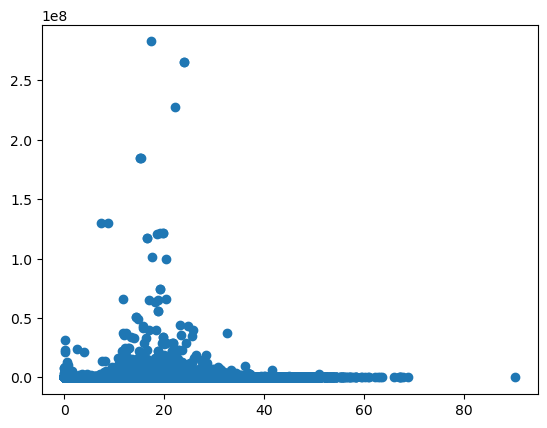

In [61]:
plt.scatter(df2['sobel_ratio'], df2['sobel_max'])

In [66]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

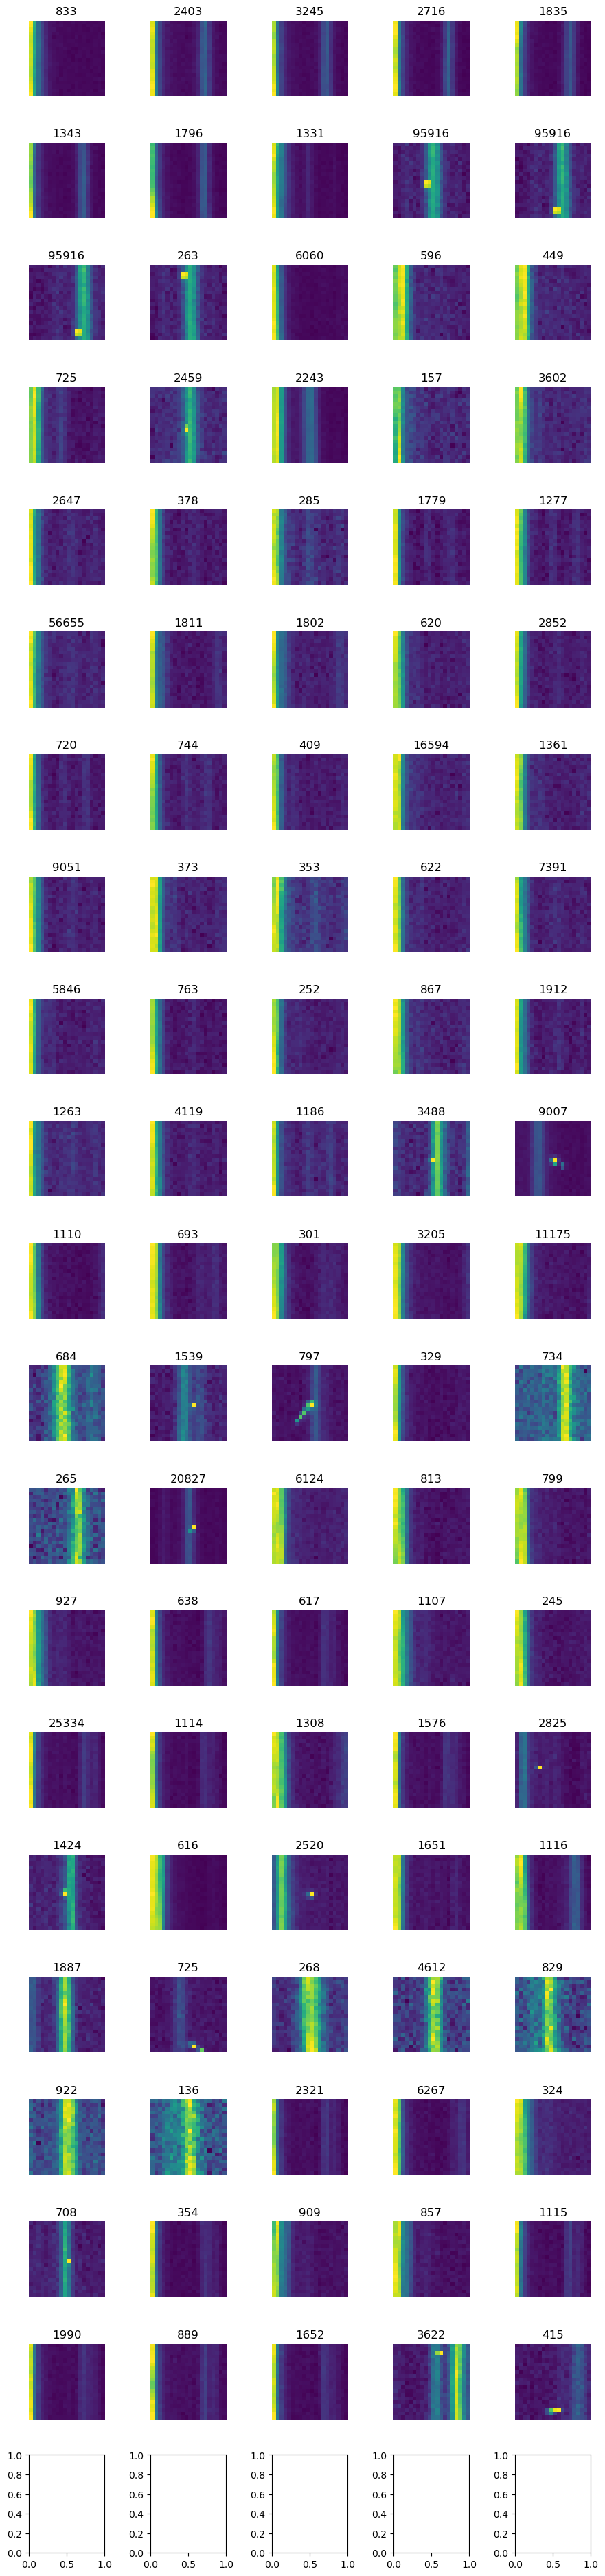

In [69]:
rff.inspect_df_with_quadrant(df_high[df_high['sobel_ratio']<5][:100], direcname='1020', titlecol='sobel_max')

In [78]:
def add_mult_sobels(df):
    mults = []
    for i, row in df.iterrows():
         mults.append(sobels_to_array(row['sobels_x'])/sobels_to_array(row['sobels_y']))
    df['multi_sobels']=mults
    return df

In [82]:
df1.iloc[0]['multi_sobels']

array([[ 9.44815447e+00,  2.78342499e+01,  9.75675449e+01,
        -2.53771925e+01, -1.75123950e+01, -8.13236403e+01,
        -1.24509152e+01, -1.04277583e+01,  2.74101517e-01,
         9.81828067e-01, -1.04962149e+00,  2.21024997e-01,
         1.03281286e+01,  1.48000527e+01, -2.86326892e+01,
        -3.28059379e+00, -2.33921753e+00,  9.24677943e+00,
         4.46126679e+00,  9.08866900e-01],
       [ 4.61776233e+00,  1.80533151e+01,  5.74329653e+01,
         2.71371494e+02,  1.81366171e+02,  5.88435277e+01,
         1.02428588e+01,  3.35289349e+00,  9.56400466e-01,
         7.74541823e-02, -1.49319982e+00, -3.16612007e+00,
         2.15699256e+01, -1.10018449e+00, -1.41260036e+00,
         1.91641506e+00, -2.06798734e+00, -3.45483916e+00,
        -1.41312349e+00, -2.32569283e+00],
       [ 1.06894261e+01,  4.98262332e+01,  6.57734908e+01,
         2.33116571e+01,  3.27927373e+01, -3.20442981e+01,
        -2.67592466e+02,  4.64257947e+00, -5.44924418e+00,
         5.96355694e-03,  2.4

In [88]:
df1 = add_mult_sobels(df_high[df_high['sobel_ratio']<5][:100])

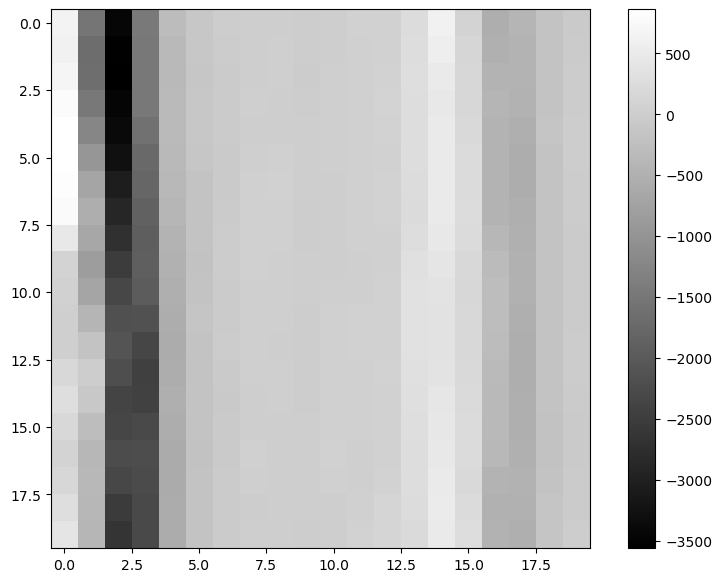

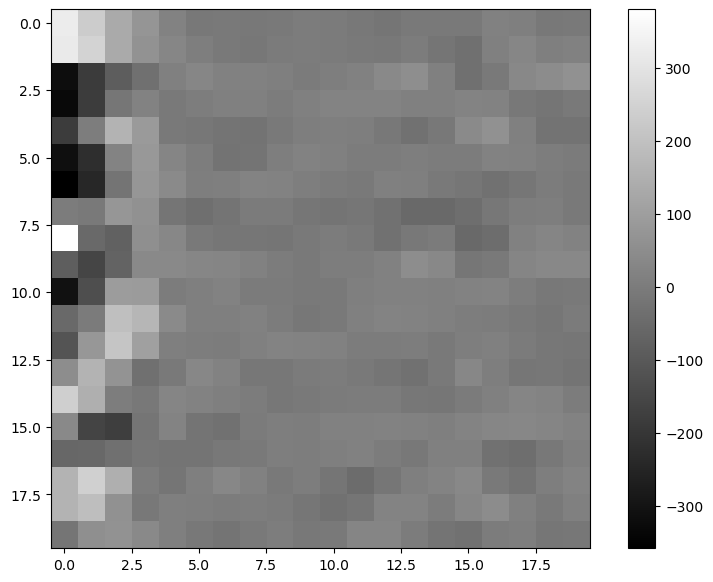

In [109]:
# plt.imshow(1/(df1.iloc[77]['multi_sobels']))
index = 79
plt.imshow(sobels_to_array(df1.iloc[index]['sobels_x']))
plt.colorbar()
plt.show()
plt.imshow(sobels_to_array(df1.iloc[index]['sobels_y']))
plt.colorbar()
plt.show()

In [111]:
def add_stdv_sobels(df):
    df['sobel_stdv_x'] = np.zeros(len(df))
    df['sobel_stdv_y'] = np.zeros(len(df))
    for i, row in df.iterrows():
        df['sobel_stdv_x'].loc[i] = np.std(sobels_to_array(row['sobels_x']))
        df['sobel_stdv_y'].loc[i] = np.std(sobels_to_array(row['sobels_y']))
                                           # /sobels_to_array(row['sobels_y']))
    return df

In [112]:
df1 = add_stdv_sobels(df1)

/tmp/ipykernel_57915/1820352991.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['sobel_stdv_x'].loc[i] = np.std(sobels_to_array(row['sobels_x']))
/tmp/ipykernel_57915/1820352991.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['sobel_stdv_y'].loc[i] = np.std(sobels_to_array(row['sobels_y']))


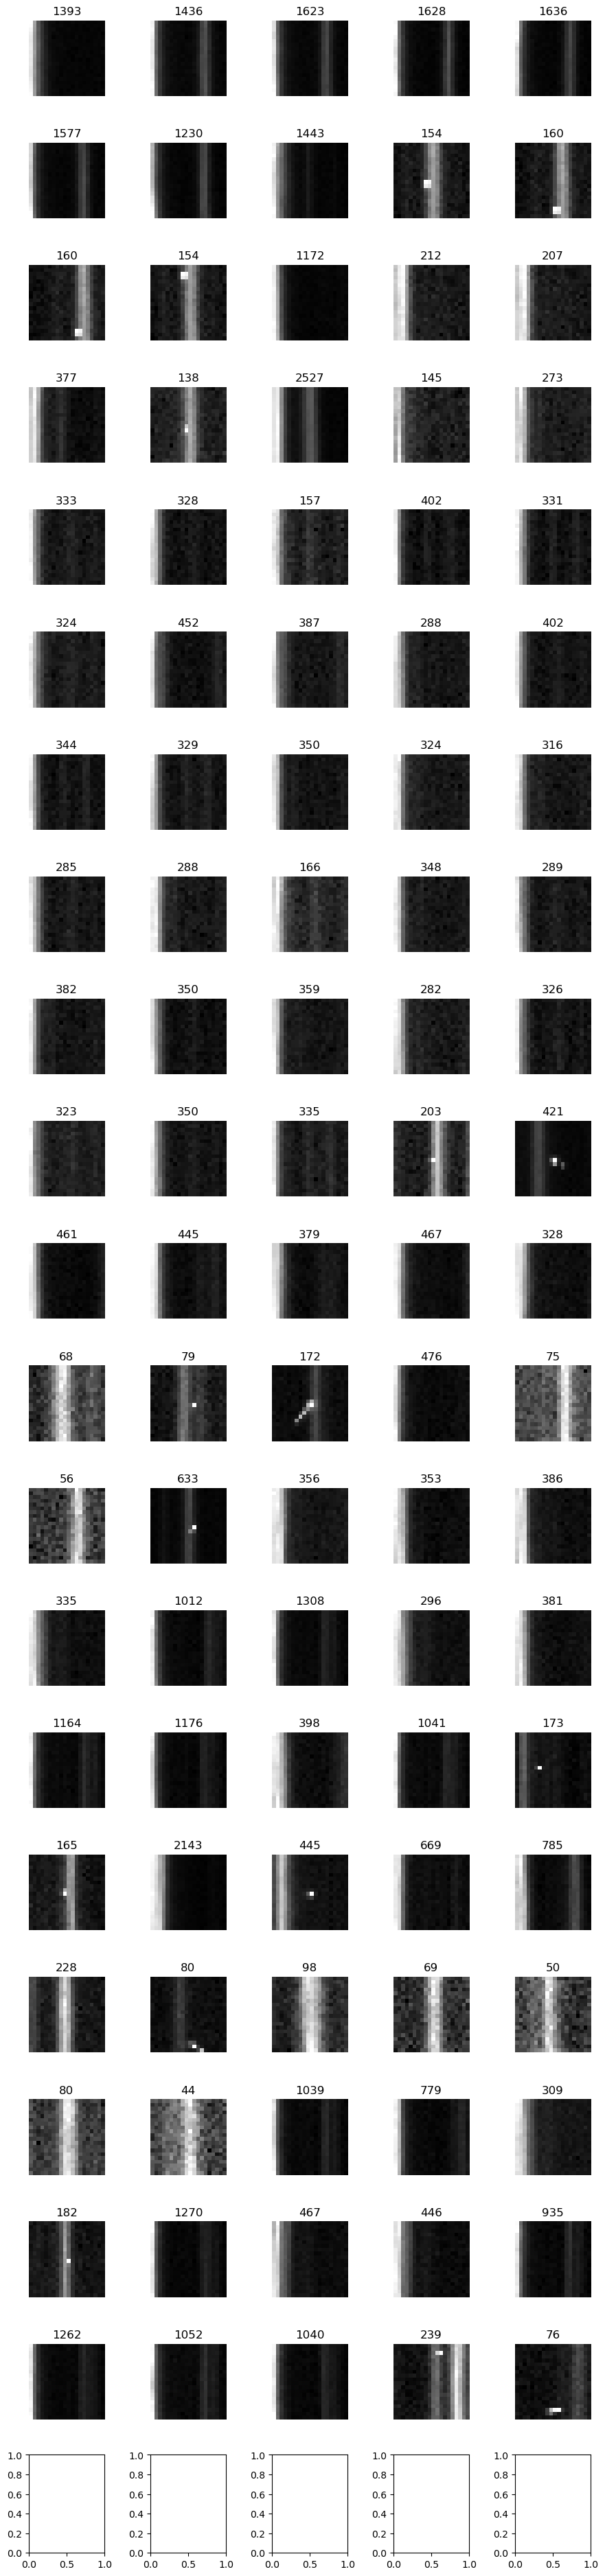

In [114]:
rff.inspect_df_with_quadrant(df1, direcname='1020', titlecol='sobel_stdv_x')

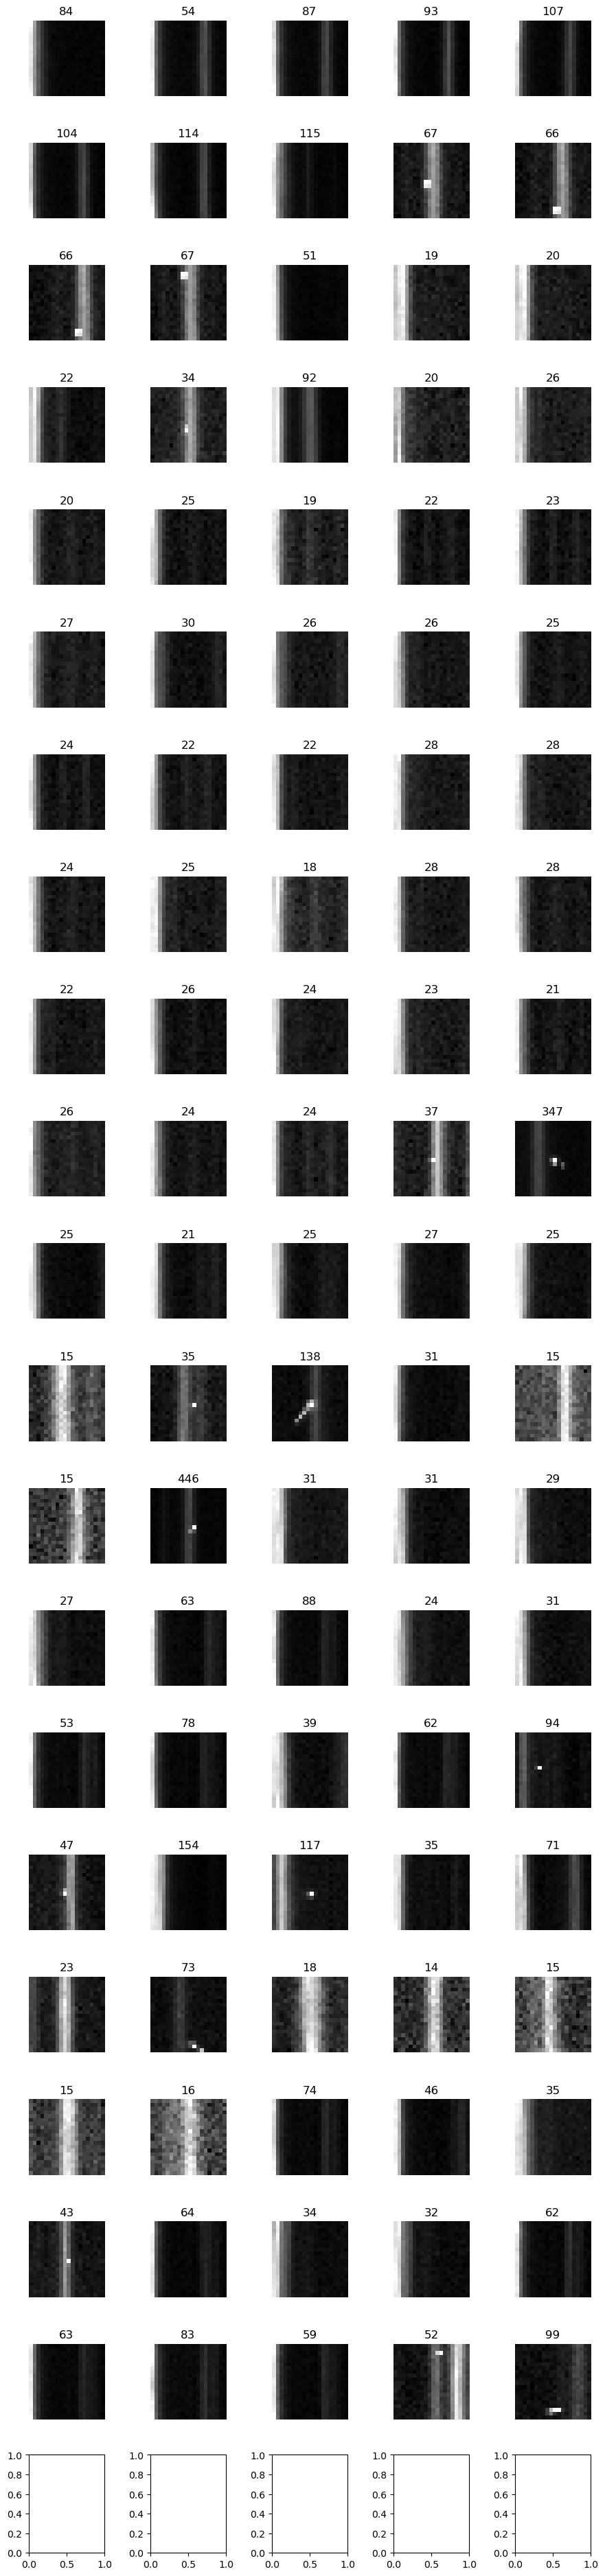

In [115]:
rff.inspect_df_with_quadrant(df1, direcname='1020', titlecol='sobel_stdv_y')

In [118]:
def add_stdv_sobel_rat(df):
    df['sobel_stdv_rat'] = np.zeros(len(df))
    for i, row in df.iterrows():
        df['sobel_stdv_rat'].loc[i] = df['sobel_stdv_x'].loc[i]/df['sobel_stdv_y'].loc[i]
    return df

In [120]:
df1 = add_stdv_sobel_rat(df1)

/tmp/ipykernel_57915/1702073631.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['sobel_stdv_rat'].loc[i] = df['sobel_stdv_x'].loc[i]/df['sobel_stdv_y'].loc[i]


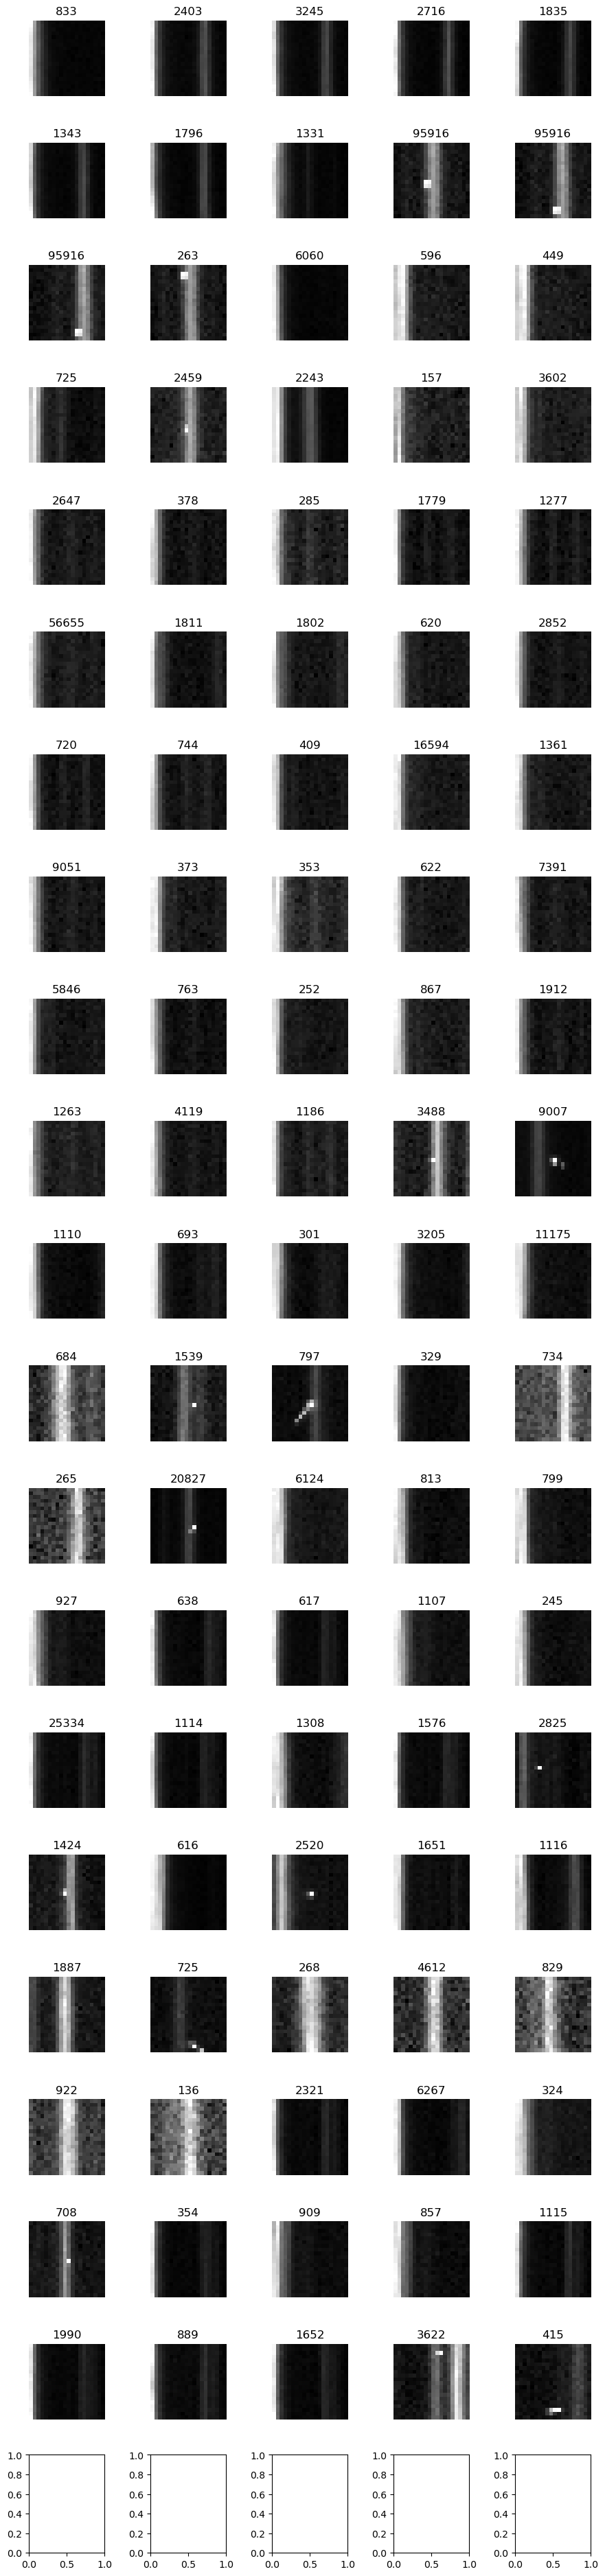

In [123]:
rff.inspect_df_with_quadrant(df1, direcname='1020', titlecol='sobel_max')

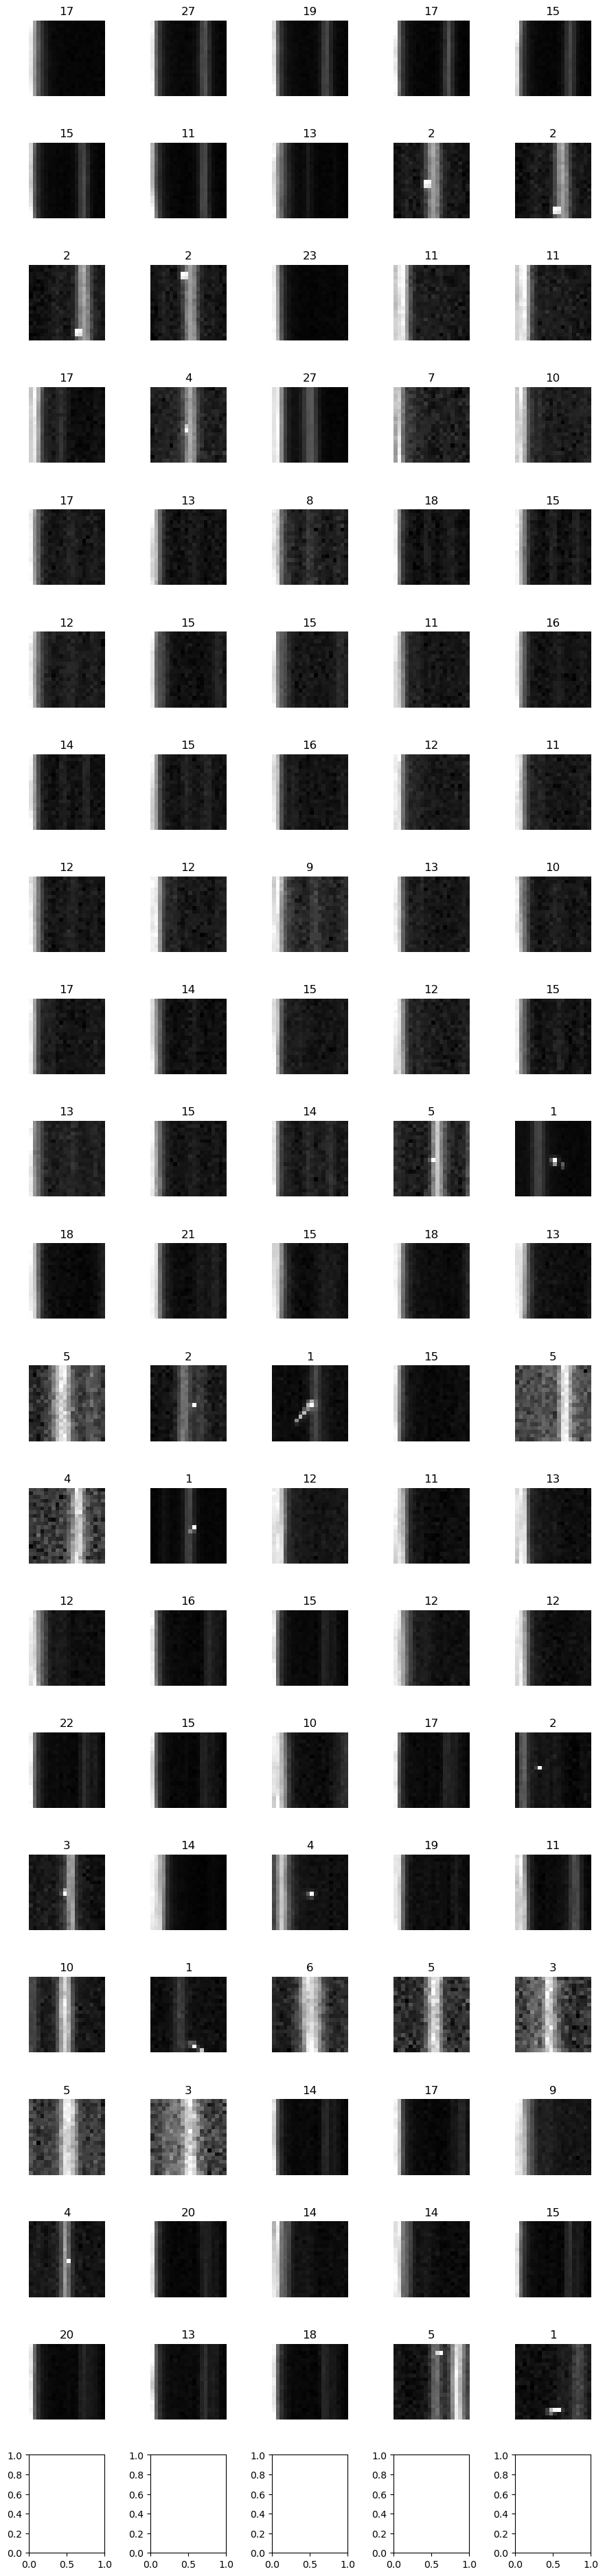

In [121]:
rff.inspect_df_with_quadrant(df1, direcname='1020', titlecol='sobel_stdv_rat')

In [122]:
df1

,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,...,signal_local_new,sobel_ratio,sobels_x,sobels_y,quadrant,sobel_max,multi_sobels,sobel_stdv_x,sobel_stdv_y,sobel_stdv_rat
164,164,164,164,164,164,164,ztf_20221020297847_000449_zr_c15_x_0006.,4,pos,1892.0,...,32.150036,0.081664,[[-3.94117090e+03 -6.17864600e+03 -2.98530591e...,[[-1.15454712e+02 -8.52572327e+01 2.47769165e...,4,833.294078,"[[34.136076663549254, 72.4706374383648, -1204....",1392.540529,83.589754,16.659225
2052,2052,2052,2052,2052,2052,26,ztf_20221020294271_000449_zr_c04_x_0029.,3,pos,619.0,...,9.151868,2.502209,[[-4.14503320e+03 -5.10088379e+03 -1.24061719e...,[[ 9.25208130e+01 3.75461731e+01 -1.10618591e...,3,2402.790273,"[[-44.80108924248212, -135.85629023800564, 112...",1435.688563,53.745838,26.712553
2053,2053,2053,2053,2053,2053,27,ztf_20221020294271_000449_zr_c04_x_0029.,3,pos,637.5,...,9.712359,1.340248,[[-4.46568848e+03 -5.46190527e+03 -1.28659912e...,[[ 3.99131470e+01 2.25103455e+01 1.67498627e...,3,3245.265456,"[[-111.88515102555054, -242.63977956269042, -7...",1622.513013,87.064085,18.635848
2057,2057,2057,2057,2057,2057,31,ztf_20221020294271_000449_zr_c04_x_0029.,3,pos,790.0,...,12.663104,1.689790,[[-5.14216895e+03 -6.24507520e+03 -1.45057275e...,[[ 1.51246277e+02 2.60835876e+01 -2.83046875e...,3,2716.326392,"[[-33.998648112177996, -239.425469217279, 51.2...",1628.180683,93.279002,17.454954
2061,2061,2061,2061,2061,2061,35,ztf_20221020294271_000449_zr_c04_x_0029.,3,pos,853.5,...,8.602896,1.831722,[[-5.21633105e+03 -6.62132520e+03 -1.86510657e...,[[ 6.49915771e+01 3.88381348e+01 -2.26810608e...,3,1834.939342,"[[-80.26164747431555, -170.48514904479916, 82....",1636.070750,106.923761,15.301283
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22312,22312,22312,22312,22312,22312,623,ztf_20221020154120_000640_zi_c08_x_0004.,3,pos,2331.5,...,6.563178,0.640620,[[-3.76249072e+03 -4.71526465e+03 -1.19274158e...,[[-2.39479858e+02 -1.23194000e+02 -2.03192902e...,3,1990.170190,"[[15.711094667510617, 38.27511607708168, 58.69...",1261.654981,62.698423,20.122595
22341,22341,22341,22341,22341,22341,652,ztf_20221020154120_000640_zi_c08_x_0004.,3,pos,2413.0,...,12.257314,0.535119,[[-3.66632495e+03 -4.25238916e+03 -7.14072632e...,[[-3.85818176e+01 4.23612976e+01 4.41407776e...,3,889.434573,"[[95.0272739353783, -100.38382676927252, -16.1...",1052.105400,83.347718,12.623086
22377,22377,22377,22377,22377,22377,688,ztf_20221020154120_000640_zi_c08_x_0004.,3,pos,2549.0,...,7.082603,0.700834,[[-3.26739038e+03 -4.05975171e+03 -9.94381836e...,[[-6.84967041e+00 -1.57297668e+01 -1.42288818e...,3,1651.515646,"[[477.01424804759324, 258.09357262689997, 69.8...",1040.012794,58.642338,17.734845
23541,23541,23541,23541,23541,23541,259,ztf_20221020148032_000686_zg_c01_x_0014.,1,neg,2894.0,...,7.468260,1.418784,[[-4.07504272e+00 -1.95189056e+01 -7.72250366e...,[[-1.03360901e+01 -2.66392517e+00 3.48248291e...,1,3622.271806,"[[0.39425379235035884, 7.327122330542039, -2.2...",238.573212,51.580709,4.625241


In [ ]:
rff.inspect_df_with_quadrant(nosats[nosats['satellite_flag_2_2_new']!=1].sort_values("snr_local_new", ascending=False)[:200], "1020", imgsize=20, star=False, clim=None)


In [3]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [6]:
#from rff



In [3]:
df = df[:5]
direcname = '1020'
for filename, group in df.groupby('filename'):     
        fpath = (
            "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
            + direcname
            + "_minus_extras/"
        )
        path = fpath + filename+'fits.fz'
        print(path)
        break

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/ztf_20221020297847_000449_zr_c15_x_0006.fits.fz


In [4]:
hdul = fits.open(path)

In [5]:
hdul[1].header

XTENSION= 'IMAGE   '           / IMAGE extension                                
BITPIX  =                  -32 / number of bits per data pixel                  
NAXIS   =                    2 / number of data axes                            
NAXIS1  =                 3072 / length of data axis 1                          
NAXIS2  =                 3080 / length of data axis 2                          
PCOUNT  =                    0 / required keyword; must = 0                     
GCOUNT  =                    1 / required keyword; must = 1                     
EXTNAME = '1       '                                                            
HDUVERS =                    1                                                  
CCD_ID  =                   15 / ID value of CCD detector                       
CCDNAME = 'S15     '           / Detector name or serial number                 
AMP_ID  =                    0 / ID value of CCD amplifier                      
AMP_NAME= 'F       '        

In [14]:
df['quadrant']=df['quad']

In [7]:
df2 = add_stamps(df)

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/ztf_20221020297847_000449_zr_c15_x_0006.fits.fz


In [8]:
df2

,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,...,noise_global_new,local_average_outside_new,height_new,FWHM_new,signal_local_new,sobel_ratio,sobels_x,sobels_y,stamps,norm_stamps
0,0,0,0,0,0,0,ztf_20221020297847_000449_zr_c15_x_0006.,4,pos,22.5,...,173.574933,4882.454302,46.230269,3.0,8.235806,0.070364,[[-2.41276709e+03 -4.34487305e+03 -2.70264600e...,[[-2.55369141e+02 -1.56098083e+02 -2.77002563e...,"[[1638.4576, 1027.8176, 534.8699, 337.42624, 2...","[[0.16955948, 0.102558635, 0.048471272, 0.0268..."
1,1,1,1,1,1,1,ztf_20221020297847_000449_zr_c15_x_0006.,4,pos,38.0,...,173.548992,4884.812466,234.376987,4.0,23.913166,0.066571,[[-4.6783374e+03 -6.0346504e+03 -2.1098984e+03...,[[ 1.33702271e+02 3.37165527e+01 -3.93099976e...,"[[2011.134, 856.04456, 512.9731, 327.48026, 25...","[[0.2104504, 0.0837113, 0.046068706, 0.0257160..."
2,2,2,2,2,2,2,ztf_20221020297847_000449_zr_c15_x_0006.,4,pos,56.0,...,173.192475,4931.692722,91.725247,9.0,23.834532,0.071050,[[-4.67083252e+03 -6.96546143e+03 -2.97817651e...,[[ 9.62821045e+01 5.29211731e+01 -3.58135681e...,"[[2219.1465, 1048.8724, 491.18735, 313.10593, ...","[[0.23327401, 0.10486882, 0.043678325, 0.02413..."
3,3,3,3,3,3,3,ztf_20221020297847_000449_zr_c15_x_0006.,4,pos,76.0,...,172.979198,4964.279553,145.598376,7.0,25.431341,0.056856,[[-2.68699951e+03 -5.57041455e+03 -3.70847705e...,[[ 7.75968018e+01 1.37770691e+02 1.45457489e...,"[[1914.9579, 1236.7316, 513.7873, 316.25763, 2...","[[0.19989772, 0.12548116, 0.04615804, 0.024484..."
4,4,4,4,4,4,4,ztf_20221020297847_000449_zr_c15_x_0006.,4,pos,77.5,...,548.658066,17498.340405,844.737720,6.0,57.800358,21.066544,[[ 2.71482697e+01 3.14926147e+01 -2.67562866e...,[[ 3.57486725e+01 1.53379822e+01 9.51304626e...,"[[157.44589, 166.4001, 168.25458, 164.85391, 1...","[[0.0070594363, 0.008041913, 0.008245391, 0.00..."


In [10]:
newdf = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/df_stamps")

In [11]:
newdf

,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,type,...,noise_global_new,local_average_outside_new,height_new,FWHM_new,signal_local_new,sobel_ratio,sobels_x,sobels_y,stamp,norm_stamp
0,0,0,0,0,0,0,0,ztf_20221020297847_000449_zr_c15_x_0006.,4,pos,...,173.574933,4882.454302,46.230269,3.0,8.235806,0.070364,[[-2.41276709e+03 -4.34487305e+03 -2.70264600e...,[[-2.55369141e+02 -1.56098083e+02 -2.77002563e...,[[1638.4576 1027.8176 534.8699 337.42624 ...,[[0.16955948 0.10255864 0.04847127 0.0268073 ...
1,1,1,1,1,1,1,1,ztf_20221020297847_000449_zr_c15_x_0006.,4,pos,...,173.548992,4884.812466,234.376987,4.0,23.913166,0.066571,[[-4.6783374e+03 -6.0346504e+03 -2.1098984e+03...,[[ 1.33702271e+02 3.37165527e+01 -3.93099976e...,[[2011.134 856.04456 512.9731 327.48026 ...,[[0.2104504 0.0837113 0.04606871 0.025716 ...
2,2,2,2,2,2,2,2,ztf_20221020297847_000449_zr_c15_x_0006.,4,pos,...,173.192475,4931.692722,91.725247,9.0,23.834532,0.071050,[[-4.67083252e+03 -6.96546143e+03 -2.97817651e...,[[ 9.62821045e+01 5.29211731e+01 -3.58135681e...,[[2219.1465 1048.8724 491.18735 313.10593 ...,[[0.23327401 0.10486882 0.04367832 0.02413882 ...
3,3,3,3,3,3,3,3,ztf_20221020297847_000449_zr_c15_x_0006.,4,pos,...,172.979198,4964.279553,145.598376,7.0,25.431341,0.056856,[[-2.68699951e+03 -5.57041455e+03 -3.70847705e...,[[ 7.75968018e+01 1.37770691e+02 1.45457489e...,[[1914.9579 1236.7316 513.7873 316.25763 ...,[[0.19989772 0.12548116 0.04615804 0.02448463 ...
4,4,4,4,4,4,4,4,ztf_20221020297847_000449_zr_c15_x_0006.,4,pos,...,548.658066,17498.340405,844.737720,6.0,57.800358,21.066544,[[ 2.71482697e+01 3.14926147e+01 -2.67562866e...,[[ 3.57486725e+01 1.53379822e+01 9.51304626e...,[[ 157.44589 166.4001 168.25458 164.85391 ...,[[0.00705944 0.00804191 0.00824539 0.00787226 ...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
894770,894770,894770,894770,894770,894770,894770,290,ztf_20221020157697_000640_zi_c13_x_0026.,1,neg,...,215.614237,8186.534746,622.925215,7.0,54.777488,19.799755,[[-1.14337311e+01 3.41336060e+01 3.33304596e...,[[ 1.68879852e+01 2.45683899e+01 -8.54048157e...,[[ 151.83536 144.56664 162.85895 158.68628 ...,[[0.01379773 0.01226981 0.01611494 0.01523782 ...
894771,894771,894771,894771,894771,894771,894771,291,ztf_20221020157697_000640_zi_c13_x_0026.,1,neg,...,215.614237,8186.534746,622.925215,7.0,54.777488,17.971455,[[-1.32104492e+00 -9.30337524e+00 2.75077362e...,[[ 1.80271606e+01 1.52462769e+00 -1.19028473e...,[[ 154.98975 157.51266 153.93636 166.47401 ...,[[0.0144608 0.01499112 0.01423937 0.01687484 ...
894772,894772,894772,894772,894772,894772,894772,292,ztf_20221020157697_000640_zi_c13_x_0026.,1,neg,...,216.423502,8119.098433,531.360552,5.0,41.358593,20.052870,[[ 2.96071320e+01 3.53159637e+01 5.80841370e...,[[-1.40624847e+01 -2.82426605e+01 -1.30426941e...,[[ 153.38054 165.19547 161.34143 176.7846 ...,[[0.01412253 0.01660608 0.01579595 0.01904217 ...
894773,894773,894773,894773,894773,894773,894773,293,ztf_20221020157697_000640_zi_c13_x_0026.,1,neg,...,216.315554,8108.029619,137.210615,20.0,60.813356,21.838806,[[ 1.38533020e+00 8.34553528e+00 4.32852478e...,[[-1.86070251e+00 2.92594910e+00 -2.20394897e...,[[ 154.83821 154.02936 156.88312 166.17462 ...,[[0.01442894 0.01425892 0.01485879 0.0168119 ...


In [12]:
def justxy(stamp):
    Lx = sobel(stamp, axis=1)  # column axis
    Ly = sobel(stamp, axis=0)  # rows axis
    # sobel_ratio = np.max(Lx) / np.max(Ly)  # we want this to be as large as possible
    return Lx, Ly

In [19]:
sobels_to_array(newdf['stamp'].loc[0])

array([[1638.4576 , 1027.8176 ,  534.8699 ,  337.42624,  250.39296,
         199.3034 ,  174.967  ,  166.19171,  168.09468,  167.22797,
         160.01872,  167.52908,  160.9665 ,  159.79425,  168.3669 ,
         164.03372,  161.08078,  161.17416,  160.33228,  161.2615 ],
       [1567.1671 ,  986.3201 ,  533.05743,  354.84842,  261.68445,
         192.24475,  181.5605 ,  169.84087,  158.40094,  160.60202,
         164.49957,  162.51251,  160.27652,  164.09753,  162.07169,
         171.61415,  159.62413,  163.60025,  156.3386 ,  167.82951],
       [1486.5885 ,  992.6527 ,  528.2965 ,  340.3699 ,  246.9941 ,
         199.8279 ,  172.03796,  160.03294,  165.53842,  154.99277,
         159.26544,  169.0776 ,  160.57684,  158.31444,  161.17899,
         162.9584 ,  167.2102 ,  160.3737 ,  160.0073 ,  158.20155],
       [1502.6263 ,  984.7396 ,  521.8556 ,  339.58896,  256.23578,
         200.63412,  179.7946 ,  165.49576,  155.9277 ,  172.20726,
         162.4867 ,  164.05923,  158.04407,  

In [20]:
def normarray(arr):
    return (arr-np.min(arr))/(np.max(arr)-np.min(arr))

In [22]:
def calc_sobels_from_df_stamps(df):
    '''
    okay we want three different types of sobels-
    from normal (already have that), from norm over
    full image, and from norm over part image
    eventually we'll just want the min max whatever
    '''
    Lxn = []
    Lyn = []
    Lxnn = []
    Lynn = []
    for i, row in df.iterrows():
        normstamp = sobels_to_array(row['norm_stamp'])
        normnormstamp = normarray(sobels_to_array(row['stamp']))
        xnorm, ynorm = justxy(normstamp)
        xnormnorm, ynormnorm = justxy(normnormstamp)
        Lxn.append(xnorm)
        Lyn.append(ynorm)
        Lxnn.append(xnormnorm)
        Lynn.append(ynormnorm)
        
    df['Lxnorm']=Lxn
    df['Lynorm']=Lyn
    df['Lxnormnorm']=Lxnn
    df['Lynormnorm']=Lynn
    return df

In [24]:
wsobs = calc_sobels_from_df_stamps(newdf[:5])

/tmp/ipykernel_60737/1824240099.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Lxnorm']=Lxn
/tmp/ipykernel_60737/1824240099.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Lynorm']=Lyn
/tmp/ipykernel_60737/1824240099.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-

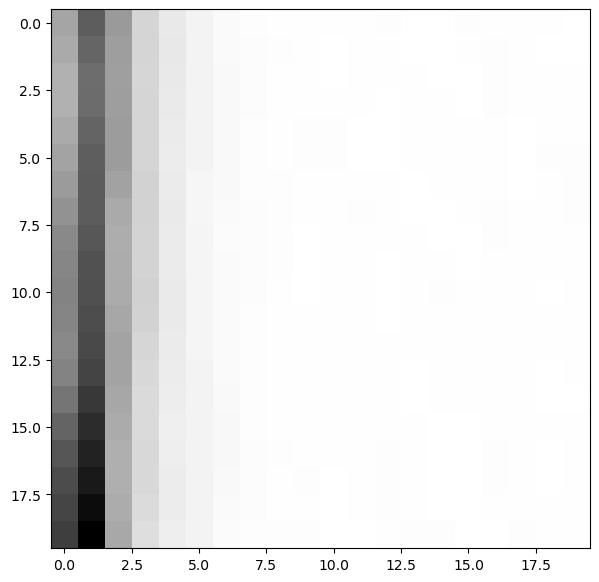

In [26]:
plt.imshow(wsobs.iloc[0]['Lxnorm'])

In [112]:
def inspect_df_w_stamp(df, imgsize=10, star=False, clim=None, plot="stamp", norm=False, titlecol=[]):
    """
    plots the stamps corresponding to detections in a dataframe
    no limit, so put in df[:100] or something probably to save time
    """
    wid = 10
    figcols = 5
    figrows = 1 + len(df) // figcols
    fig, ax = plt.subplots(figrows, figcols, figsize=(figcols * 1.8, figrows * 1.8))
    for i in range(figrows):
        for j in range(figcols):
            index = figcols * i + j
            if index < len(df):
                fname = df.iloc[index]["filename"] + "fits.fz"
                row = int(df.iloc[index]["row_from_nn"])
                col = int(df.iloc[index]["col_from_nn"])
                quad = int(df.iloc[index]["quadrant"])
                stamp = df.iloc[index][plot]
                
                # print(type(stamp))
                if isinstance(stamp, str):
                    stamp = sobels_to_array(stamp)
                # break
                if norm:
                    stamp = normarray(stamp)
                # ax[i, j].imshow(norm[col+wid-10:col+wid+10, row-10+wid:row+10+wid])
                ax[i, j].imshow(
                        stamp, vmax=clim
                )
                if star==True:
                    starpos = df.iloc[index]['closest_x']
                    ax[i, j].scatter(starpos- (col - imgsize  + wid), 10)
                
                ax[i, j].set_axis_off()
                # ax[i, j].set_title(fname[26:-8])
                # print(titlecol)
                if titlecol==None or titlecol==[]:
                    ax[i, j].set_title(str(index))
                    # print("none")
                else:
                    # ax[i, j].set_title(str(index)+": "+str(round(df.iloc[index][titlecol])))
                    # titlestring=""
                    # for title in titlecol:
                        # print(titlecol)
                        # print(f"{df.iloc[index][title]:.0f}")
                        # titlestring=f"{titlestring}, {df.iloc[index][title]:.0f}"
                        
                        # print(titlestring)
                    titlestring=f"{[round(df.iloc[index][title]) for title in titlecol]}"

                    ax[i, j].set_title(titlestring)
    if titlecol!=None:
        fig.suptitle(titlecol)
    plt.tight_layout()
    plt.show()


In [50]:
newdf['quadrant']=newdf['quad']

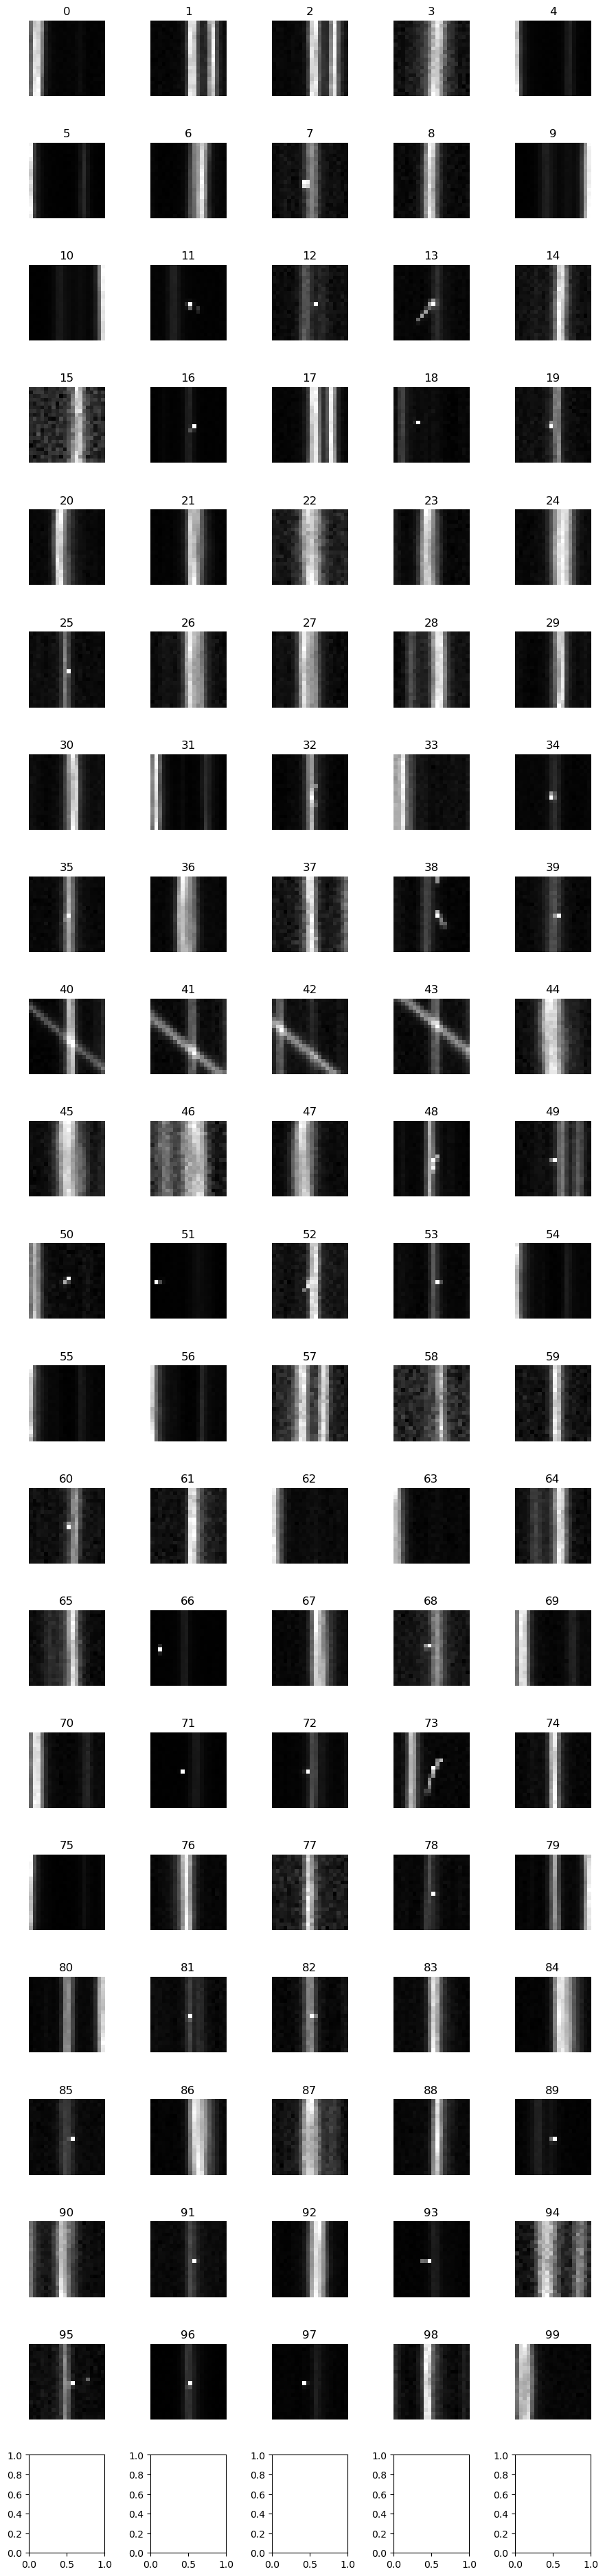

In [55]:
inspect_df_w_stamp(big[:100], norm=True)

In [51]:
big = newdf[newdf["snr_local"]>1]

In [58]:
subsection = big[:50]

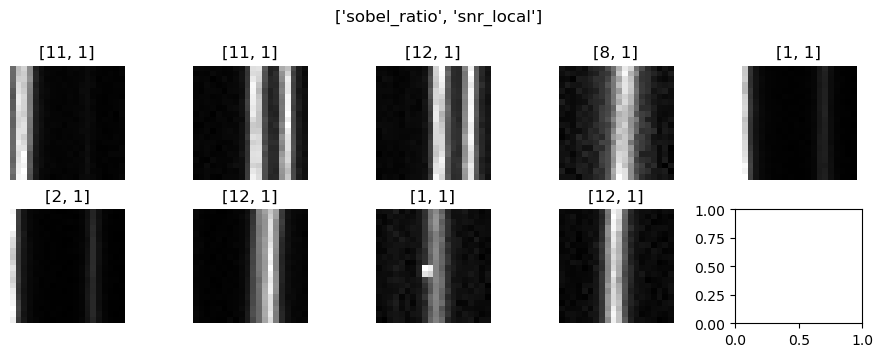

In [113]:
inspect_df_w_stamp(subsection[:9], titlecol=["sobel_ratio", "snr_local"])

In [114]:
dff = calc_sobels_from_df_stamps(subsection)

/tmp/ipykernel_60737/1824240099.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Lxnorm']=Lxn
/tmp/ipykernel_60737/1824240099.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Lynorm']=Lyn
/tmp/ipykernel_60737/1824240099.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-

In [116]:
def add_stuff(df):
    df['sobel_norm_samemax'] = np.zeros(len(df))
    df['sobel_norm_diffmax'] = np.zeros(len(df))
    df['sobel_normnorm_samemax'] = np.zeros(len(df))
    df['sobel_normnorm_diffmax'] = np.zeros(len(df))
    for i, row in df.iterrows():
        df['sobel_norm_samemax'].loc[i] = np.max(row['Lxnorm']/row['Lynorm'])
        df['sobel_norm_diffmax'].loc[i] = np.max(row['Lxnorm'])/np.max(row['Lynorm'])
        df['sobel_normnorm_samemax'].loc[i] = np.max(row['Lxnormnorm']/row['Lynormnorm'])
        df['sobel_normnorm_diffmax'].loc[i] = np.max(row['Lxnormnorm'])/np.max(row['Lynormnorm'])
        
    return df

In [117]:
dff = add_stuff(dff)

/tmp/ipykernel_60737/2695908465.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['sobel_norm_samemax'] = np.zeros(len(df))
/tmp/ipykernel_60737/2695908465.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['sobel_norm_diffmax'] = np.zeros(len(df))
/tmp/ipykernel_60737/2695908465.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pan

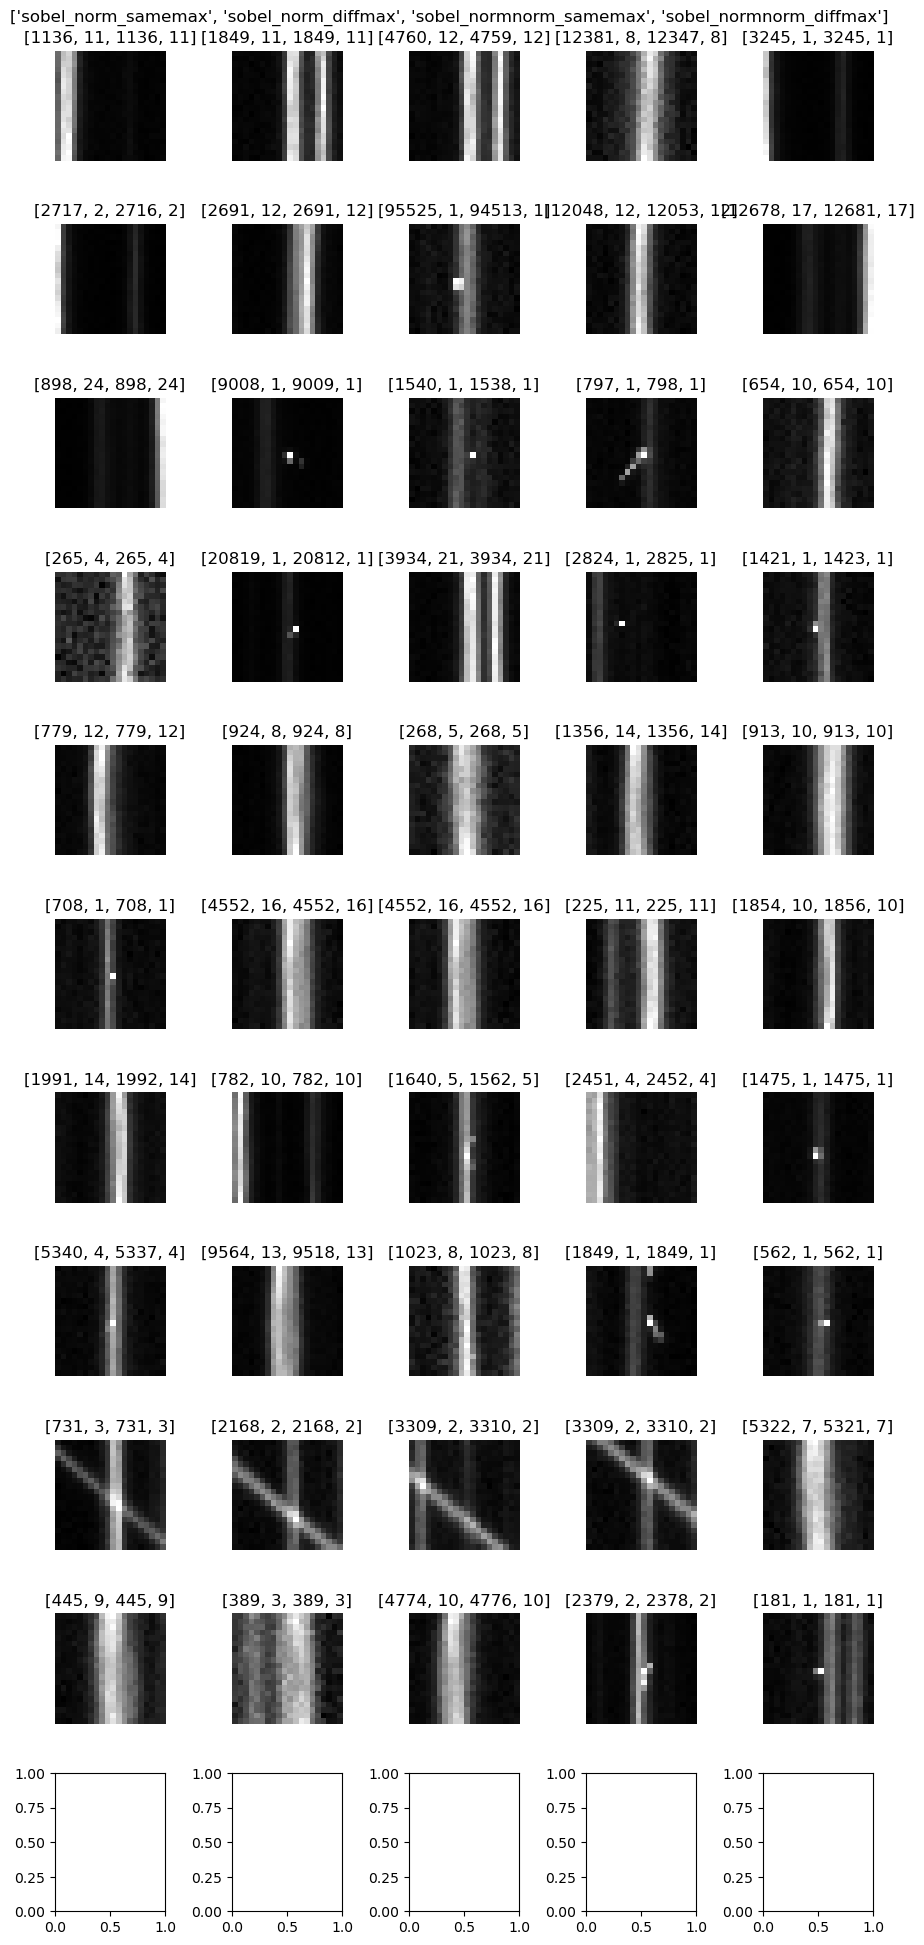

In [118]:
inspect_df_w_stamp(dff, titlecol=["sobel_norm_samemax", "sobel_norm_diffmax", "sobel_normnorm_samemax", "sobel_normnorm_diffmax"])

In [3]:
def inspect_df_w_stamp_color(df, imgsize=10, star=False, clim=None, plot="stamp", norm=False, titlecol=[]):
    """
    plots the stamps corresponding to detections in a dataframe
    no limit, so put in df[:100] or something probably to save time
    """
    # Define a color palette for different elements
    colors = ['red', 'blue', 'green', 'darkorange', 'purple', 'brown', 'deeppink', 'gray', 'olive', 'cyan']
    
    wid = 10
    figcols = 5
    figrows = 1 + len(df) // figcols
    fig, ax = plt.subplots(figrows, figcols, figsize=(figcols * 1.8, figrows * 1.8))
    for i in range(figrows):
        for j in range(figcols):
            index = figcols * i + j
            if index < len(df):
                fname = df.iloc[index]["filename"] + "fits.fz"
                row = int(df.iloc[index]["row_from_nn"])
                col = int(df.iloc[index]["col_from_nn"])
                quad = int(df.iloc[index]["quadrant"])
                stamp = df.iloc[index][plot]
                
                if isinstance(stamp, str):
                    stamp = rff.sobels_to_array(stamp)
                
                if norm:
                    stamp = normarray(stamp)
                
                ax[i, j].imshow(stamp, vmax=clim)
                
                if star==True:
                    starpos = df.iloc[index]['closest_x']
                    ax[i, j].scatter(starpos - (col - imgsize + wid), 10)
                
                ax[i, j].set_axis_off()
                
                if titlecol==None or titlecol==[]:
                    ax[i, j].set_title(str(index))
                else:
                    # Build title with proper spacing between colored values
                    num_values = len(titlecol)
                    
                    # Calculate spacing - distribute evenly across the width
                    if num_values == 1:
                        positions = [0.5]
                    else:
                        # Space them out more for better separation
                        spacing = 0.8 / (num_values - 1)  # Use 80% of width
                        positions = [0.1 + i * spacing for i in range(num_values)]
                    
                    for idx, title in enumerate(titlecol):
                        value = round(df.iloc[index][title])
                        color = colors[idx % len(colors)]
                        
                        # Place colored text at calculated position
                        ax[i, j].text(positions[idx], 1.02, str(value),
                                     transform=ax[i, j].transAxes,
                                     ha='center', va='bottom',
                                     fontsize=10, color=color, weight='bold')
    
    # Create color-coded suptitle legend
    if titlecol!=None and titlecol!=[]:
        from matplotlib.patches import Patch
        legend_elements = [Patch(facecolor=colors[idx % len(colors)], 
                                label=title) 
                          for idx, title in enumerate(titlecol)]
        fig.legend(handles=legend_elements, loc='upper center', 
                  ncol=len(titlecol), frameon=False, fontsize=10)
    
    plt.tight_layout()
    plt.show()

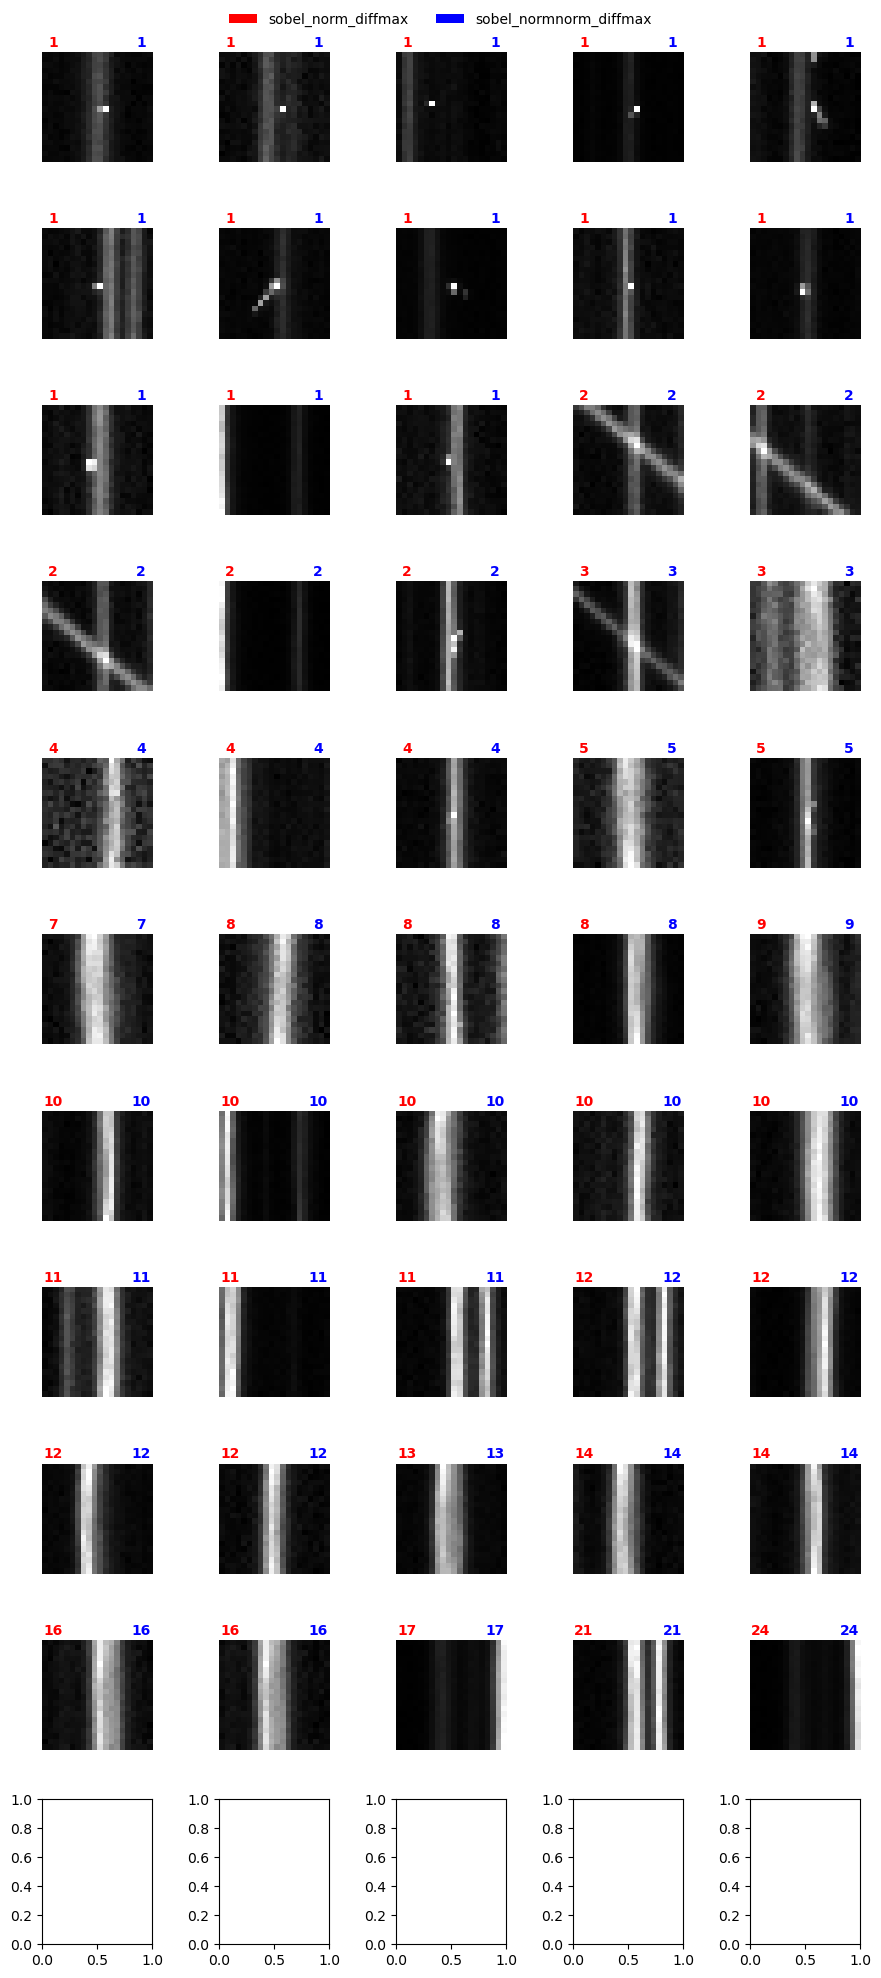

In [132]:
inspect_df_w_stamp_color(dff.sort_values("sobel_normnorm_diffmax"), titlecol=["sobel_norm_diffmax", "sobel_normnorm_diffmax"])

In [135]:
def add_more_stuff(df):
    df['sobel_norm_stdv_rat'] = np.zeros(len(df))
    # df['sobel_norm_diffmax'] = np.zeros(len(df))
    df['sobel_normnorm_stdv_rat'] = np.zeros(len(df))
    df['sobel_norm_stdv_x'] = np.zeros(len(df))
    df['sobel_norm_stdv_y'] = np.zeros(len(df))
    df['sobel_normnorm_stdv_x'] = np.zeros(len(df))
    df['sobel_normnorm_stdv_y'] = np.zeros(len(df))
    for i, row in df.iterrows():
        df['sobel_norm_stdv_rat'].loc[i] = np.std(row['Lxnorm'])/np.std(row['Lynorm'])
        df['sobel_normnorm_stdv_rat'].loc[i] = np.std(row['Lxnormnorm'])/np.std(row['Lynormnorm'])
        df['sobel_norm_stdv_x'].loc[i] = np.std(row['Lxnorm'])
        df['sobel_norm_stdv_y'].loc[i] = np.std(row['Lynorm'])
        df['sobel_normnorm_stdv_x'].loc[i] = np.std(row['Lxnormnorm'])
        df['sobel_normnorm_stdv_y'].loc[i] = np.std(row['Lynormnorm'])
                                                     
          
    return df

In [137]:
dff = add_more_stuff(dff)

/tmp/ipykernel_60737/474133966.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['sobel_norm_stdv_rat'] = np.zeros(len(df))
/tmp/ipykernel_60737/474133966.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['sobel_normnorm_stdv_rat'] = np.zeros(len(df))
/tmp/ipykernel_60737/474133966.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/

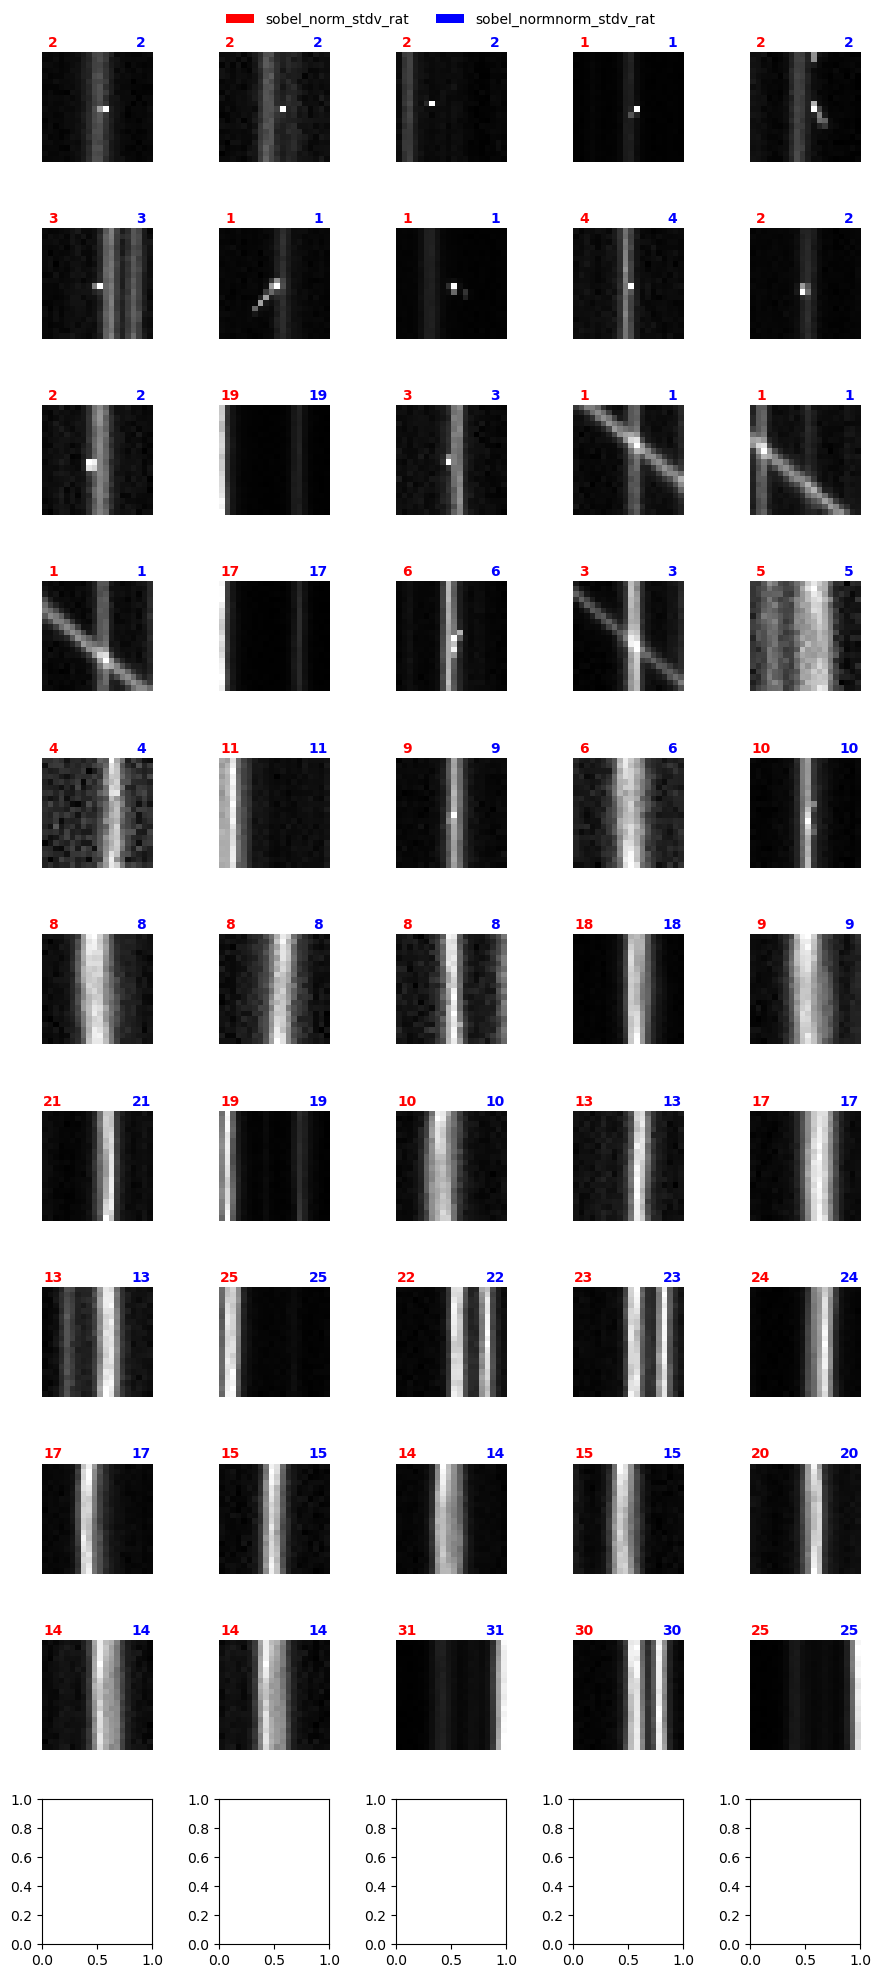

In [138]:
inspect_df_w_stamp_color(dff.sort_values("sobel_normnorm_diffmax"), titlecol=["sobel_norm_stdv_rat", "sobel_normnorm_stdv_rat"])

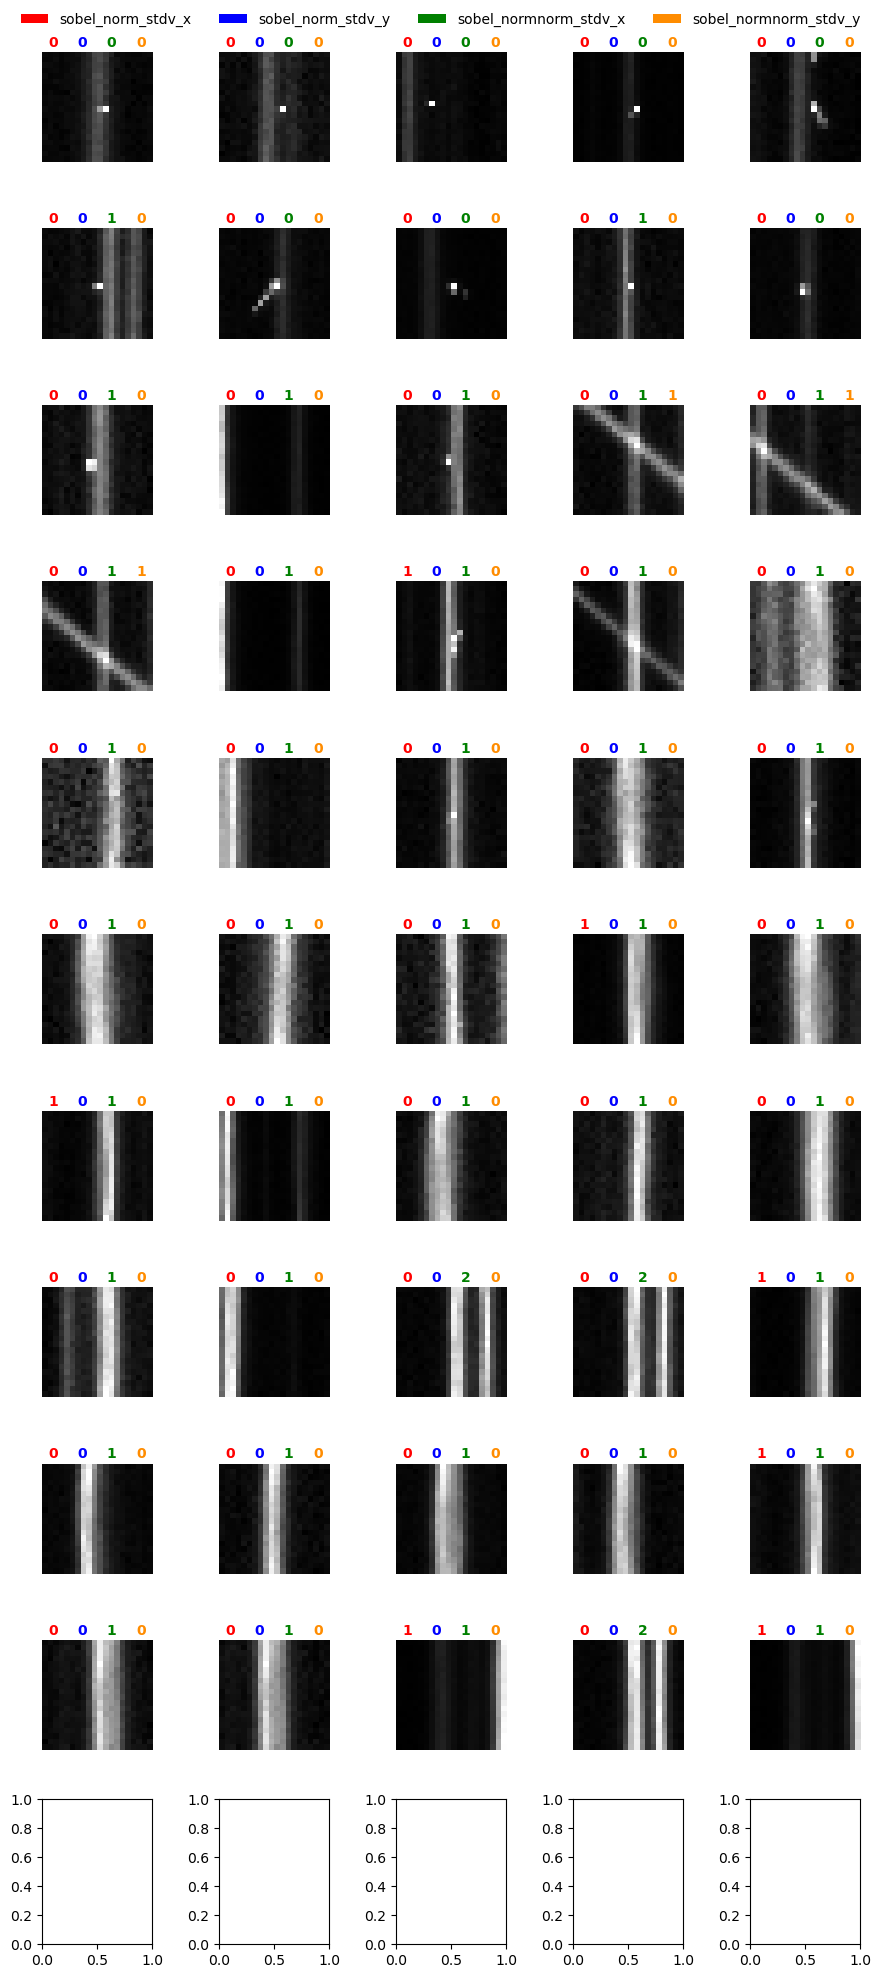

In [139]:
inspect_df_w_stamp_color(dff.sort_values("sobel_normnorm_diffmax"), titlecol=["sobel_norm_stdv_x", "sobel_norm_stdv_y", 'sobel_normnorm_stdv_x', 'sobel_normnorm_stdv_y' ])

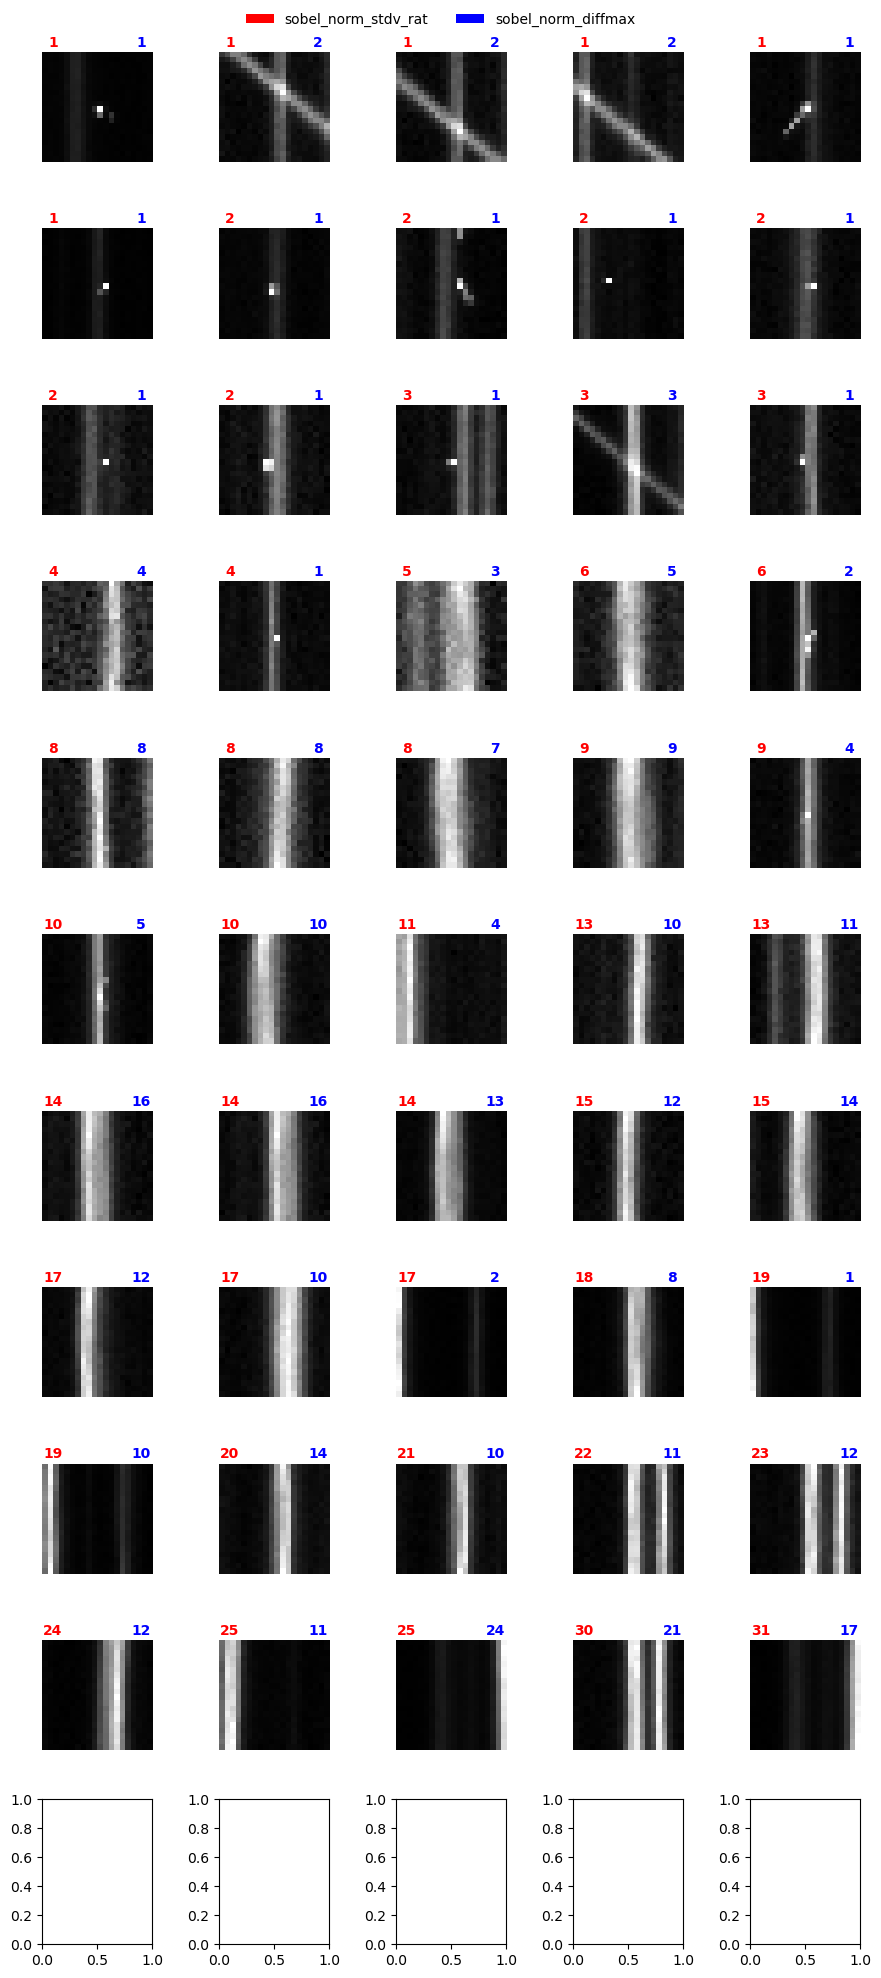

In [151]:
inspect_df_w_stamp_color(dff.sort_values("sobel_norm_stdv_rat"), titlecol=["sobel_norm_stdv_rat", "sobel_norm_diffmax"])

Int64Index([31014, 10534, 16739, 12926, 30730, 33511, 11028,  7694, 22068,
            27310,  3411,  2053, 16783, 31246, 31245, 31244,  2057, 32608,
            31242, 31679, 12680, 26485, 29290, 20539, 24894, 31535,  1973,
            30693, 19091, 31667, 23561, 23603, 31722, 11974, 20822, 23493,
              745,  1306,  1355,  2641, 18082,  3416, 29742, 20570, 23591,
            23466, 23467,  4996, 12935,  5023],
           dtype='int64')

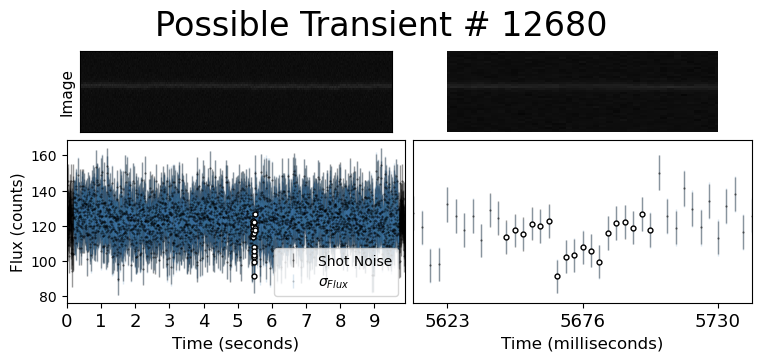

In [152]:
rff.plot_time_series_again_aperture(dff.sort_values("sobel_norm_stdv_rat"), dff.sort_values("sobel_norm_stdv_rat").index[15])

In [153]:

def add_normsobel_stuff(df):
    df['sobel_norm_stdv_rat'] = np.zeros(len(df))
    df['sobel_norm_diffmax'] = np.zeros(len(df))
    
    

    for i, row in df.iterrows():
        normstamp = sobels_to_array(row['norm_stamp'])
        xnorm, ynorm = justxy(normstamp)
        df['sobel_norm_stdv_rat'].loc[i] = np.std(xnorm)/np.std(ynorm)
        df['sobel_norm_diffmax'].loc[i] = np.max(xnorm)/np.max(ynorm)
        del normstamp, xnorm, ynorm
        gc.collect()
                                                     
          
    return df

In [156]:
dfagain = add_normsobel_stuff(newdf[:9])

/tmp/ipykernel_60737/3616932982.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['sobel_norm_stdv_rat'] = np.zeros(len(df))
/tmp/ipykernel_60737/3616932982.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['sobel_norm_diffmax'] = np.zeros(len(df))
/tmp/ipykernel_60737/3616932982.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-vi

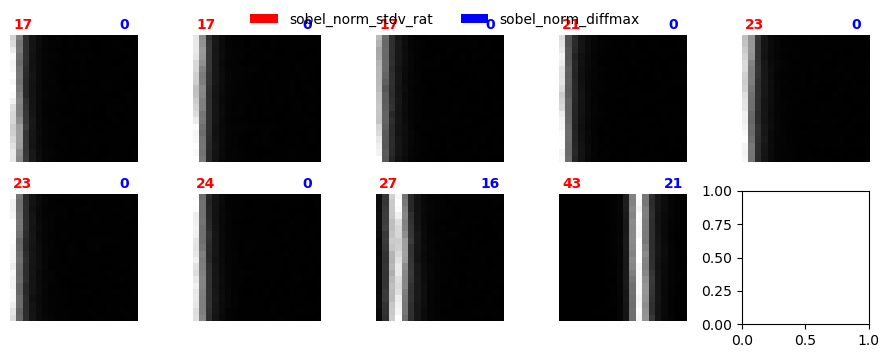

In [157]:
inspect_df_w_stamp_color(dfagain.sort_values("sobel_norm_stdv_rat"), titlecol=["sobel_norm_stdv_rat", "sobel_norm_diffmax"])

In [4]:
df = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/df_stamps_and_sobel")

In [6]:
df

,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,...,height_new,FWHM_new,signal_local_new,sobel_ratio,sobels_x,sobels_y,stamp,norm_stamp,sobel_norm_stdv_rat,sobel_norm_diffmax
0,0,0,0,0,0,0,0,0,ztf_20221020297847_000449_zr_c15_x_0006.,4,...,46.230269,3.0,8.235806,0.070364,[[-2.41276709e+03 -4.34487305e+03 -2.70264600e...,[[-2.55369141e+02 -1.56098083e+02 -2.77002563e...,[[1638.4576 1027.8176 534.8699 337.42624 ...,[[0.16955948 0.10255864 0.04847127 0.0268073 ...,17.393484,0.070364
1,1,1,1,1,1,1,1,1,ztf_20221020297847_000449_zr_c15_x_0006.,4,...,234.376987,4.0,23.913166,0.066571,[[-4.6783374e+03 -6.0346504e+03 -2.1098984e+03...,[[ 1.33702271e+02 3.37165527e+01 -3.93099976e...,[[2011.134 856.04456 512.9731 327.48026 ...,[[0.2104504 0.0837113 0.04606871 0.025716 ...,21.289004,0.066571
2,2,2,2,2,2,2,2,2,ztf_20221020297847_000449_zr_c15_x_0006.,4,...,91.725247,9.0,23.834532,0.071050,[[-4.67083252e+03 -6.96546143e+03 -2.97817651e...,[[ 9.62821045e+01 5.29211731e+01 -3.58135681e...,[[2219.1465 1048.8724 491.18735 313.10593 ...,[[0.23327401 0.10486882 0.04367832 0.02413882 ...,24.410659,0.071051
3,3,3,3,3,3,3,3,3,ztf_20221020297847_000449_zr_c15_x_0006.,4,...,145.598376,7.0,25.431341,0.056856,[[-2.68699951e+03 -5.57041455e+03 -3.70847705e...,[[ 7.75968018e+01 1.37770691e+02 1.45457489e...,[[1914.9579 1236.7316 513.7873 316.25763 ...,[[0.19989772 0.12548116 0.04615804 0.02448463 ...,17.356507,0.056856
4,4,4,4,4,4,4,4,4,ztf_20221020297847_000449_zr_c15_x_0006.,4,...,844.737720,6.0,57.800358,21.066544,[[ 2.71482697e+01 3.14926147e+01 -2.67562866e...,[[ 3.57486725e+01 1.53379822e+01 9.51304626e...,[[ 157.44589 166.4001 168.25458 164.85391 ...,[[0.00705944 0.00804191 0.00824539 0.00787226 ...,42.548746,21.066546
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
894770,894770,894770,894770,894770,894770,894770,894770,290,ztf_20221020157697_000640_zi_c13_x_0026.,1,...,622.925215,7.0,54.777488,19.799755,[[-1.14337311e+01 3.41336060e+01 3.33304596e...,[[ 1.68879852e+01 2.45683899e+01 -8.54048157e...,[[ 151.83536 144.56664 162.85895 158.68628 ...,[[0.01379773 0.01226981 0.01611494 0.01523782 ...,31.536222,19.799760
894771,894771,894771,894771,894771,894771,894771,894771,291,ztf_20221020157697_000640_zi_c13_x_0026.,1,...,622.925215,7.0,54.777488,17.971455,[[-1.32104492e+00 -9.30337524e+00 2.75077362e...,[[ 1.80271606e+01 1.52462769e+00 -1.19028473e...,[[ 154.98975 157.51266 153.93636 166.47401 ...,[[0.0144608 0.01499112 0.01423937 0.01687484 ...,27.389356,17.971451
894772,894772,894772,894772,894772,894772,894772,894772,292,ztf_20221020157697_000640_zi_c13_x_0026.,1,...,531.360552,5.0,41.358593,20.052870,[[ 2.96071320e+01 3.53159637e+01 5.80841370e...,[[-1.40624847e+01 -2.82426605e+01 -1.30426941e...,[[ 153.38054 165.19547 161.34143 176.7846 ...,[[0.01412253 0.01660608 0.01579595 0.01904217 ...,32.040525,20.052872
894773,894773,894773,894773,894773,894773,894773,894773,293,ztf_20221020157697_000640_zi_c13_x_0026.,1,...,137.210615,20.0,60.813356,21.838806,[[ 1.38533020e+00 8.34553528e+00 4.32852478e...,[[-1.86070251e+00 2.92594910e+00 -2.20394897e...,[[ 154.83821 154.02936 156.88312 166.17462 ...,[[0.01442894 0.01425892 0.01485879 0.0168119 ...,30.367197,21.838809


In [9]:
df['quadrant']=df['quad']



In [13]:
inspect_df_w_stamp_color(df.sort_values("sobel_norm_stdv_rat")[:500], titlecol=["sobel_norm_stdv_rat", "sobel_norm_diffmax"])

(array([1.4390e+03, 8.2200e+02, 6.7400e+02, 2.1250e+03, 6.6450e+03,
        1.3709e+04, 2.1180e+04, 2.9283e+04, 3.9217e+04, 5.2077e+04,
        6.6675e+04, 8.1242e+04, 9.0813e+04, 9.4953e+04, 9.1041e+04,
        8.0860e+04, 6.5774e+04, 5.0404e+04, 3.6123e+04, 2.5278e+04,
        1.6783e+04, 1.0775e+04, 6.7760e+03, 4.1980e+03, 2.4470e+03,
        1.5260e+03, 8.1700e+02, 4.7300e+02, 2.7600e+02, 1.6900e+02,
        8.3000e+01, 5.6000e+01, 3.4000e+01, 1.1000e+01, 6.0000e+00,
        7.0000e+00, 3.0000e+00, 0.0000e+00, 0.0000e+00, 1.0000e+00]),
 array([ 0.57310141,  2.68809283,  4.80308424,  6.91807566,  9.03306707,
        11.14805849, 13.2630499 , 15.37804132, 17.49303273, 19.60802415,
        21.72301556, 23.83800698, 25.9529984 , 28.06798981, 30.18298123,
        32.29797264, 34.41296406, 36.52795547, 38.64294689, 40.7579383 ,
        42.87292972, 44.98792114, 47.10291255, 49.21790397, 51.33289538,
        53.4478868 , 55.56287821, 57.67786963, 59.79286104, 61.90785246,
        64.02284

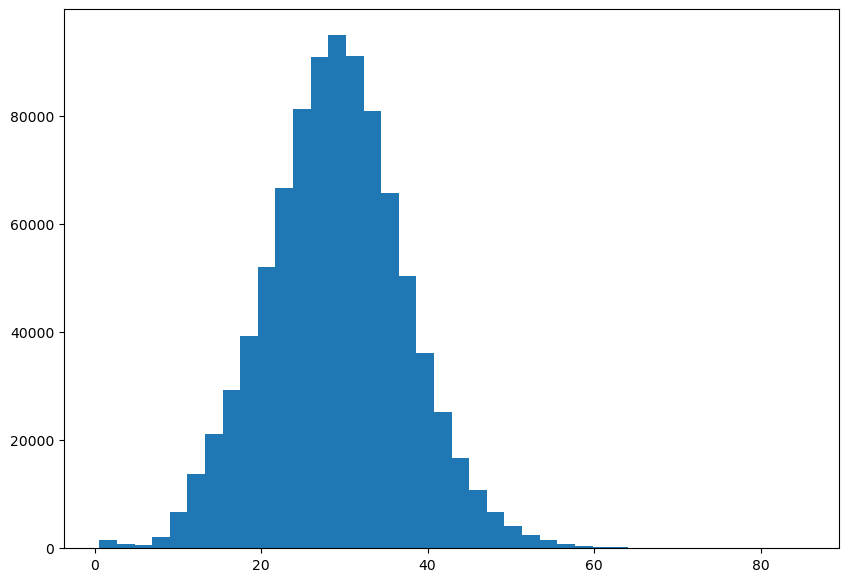

In [16]:
plt.hist(df["sobel_norm_stdv_rat"], bins=40)

Text(0.5, 1.0, 'Sobel stdv ratio - inference data')

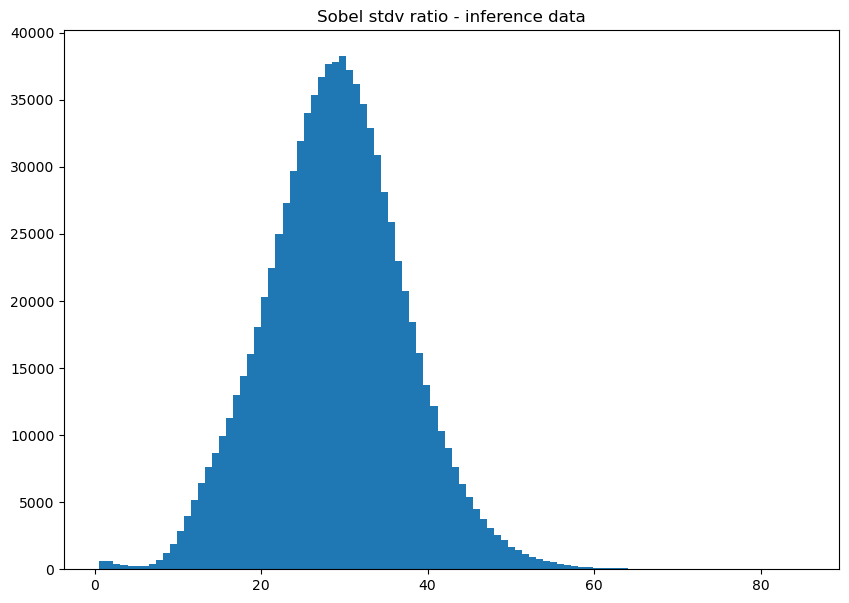

In [34]:
plt.hist(df["sobel_norm_stdv_rat"], bins=100)
# plt.xlim(-1,5)
# plt.ylim(0,1000)
plt.title("Sobel stdv ratio - inference data")

In [23]:
df_higher = df[df["sobel_norm_stdv_rat"]>2.47]

In [31]:
len(df)-len(df_higher)

1323

In [32]:
len(df)

894775

In [29]:
df_higher["tensnr_local"]=df_higher["snr_local_new"]*10

/tmp/ipykernel_8844/2416548671.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_higher["tensnr_local"]=df_higher["snr_local_new"]*10


In [1]:
df_higher.iloc[0]

NameError: name 'df_higher' is not defined

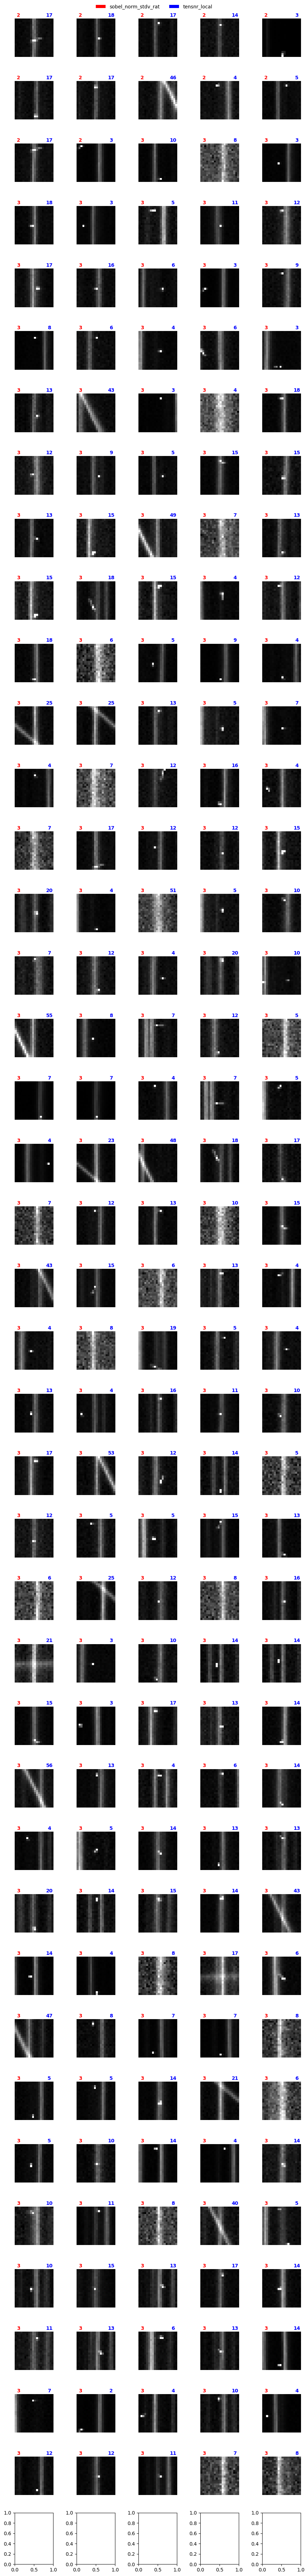

In [30]:
inspect_df_w_stamp_color(df_higher.sort_values("sobel_norm_stdv_rat")[:200], titlecol=["sobel_norm_stdv_rat", "tensnr_local"])

In [5]:
df_l3 = df[df["sobel_norm_stdv_rat"]<3]

In [8]:
df_l3["an_index"] = df_l3.index

/tmp/ipykernel_20911/767427113.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_l3["an_index"] = df_l3.index


In [10]:
df_l3['quadrant']=df_l3['quad']

/tmp/ipykernel_20911/631671111.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_l3['quadrant']=df_l3['quad']


In [12]:
len(df_l3)

1587

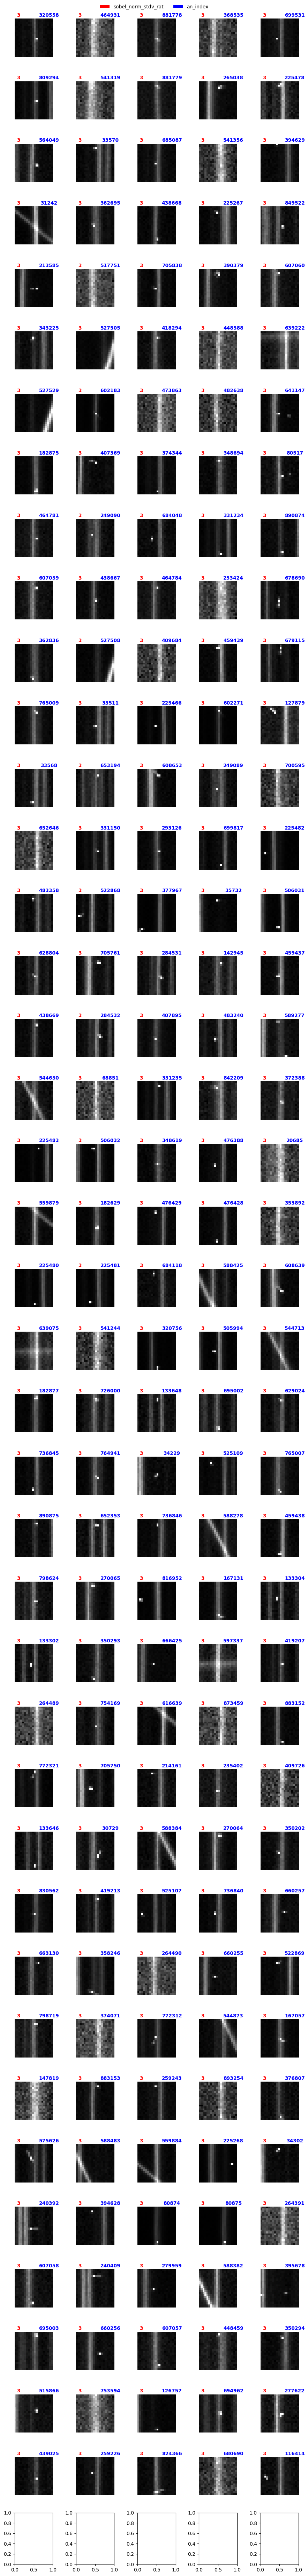

In [14]:
rff.inspect_df_w_stamp_color(df_l3.sort_values("sobel_norm_stdv_rat", ascending=False)[:200], titlecol=["sobel_norm_stdv_rat", "an_index"])

In [15]:
some_indices = [464931,
368535,
541319,
541356,
517751,
448588,
473863,
482638,
253424,
409684,
700595,
652646,
68851,
20685,
353892,
541244,
264489,
873459,
409726]

In [17]:
rff.plot_time_series_again_aperture?

Signature:
rff.plot_time_series_again_aperture(
    df,
    index,
    direcname='1020',
    half_aperture=2,
    tracking=True,
    title=None,
    plot_tracking=False,
    ylims=0,
    csv=True,
    lc_filename=None,
    fname=None,
    row=None,
    col=None,
    quad=None,
    lcfpath=None,
)
Docstring:
this plots a time series and image from a dataframe,
showing which pixels are included
inputs: dataframe, index, directory where the images live
aperture is 2*half_aperture+1
tracking can be True (tracks with brightest pixel)
or False (constant streak center pixel)
outputs: none, but plots.
NOTE: now uses loc intead of iloc, so it corresponds to the actual index!!
File:      ~/rwe/review_findings_functions.py
Type:      function

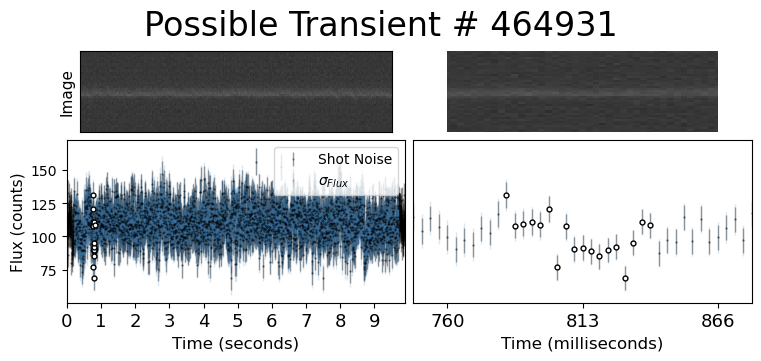

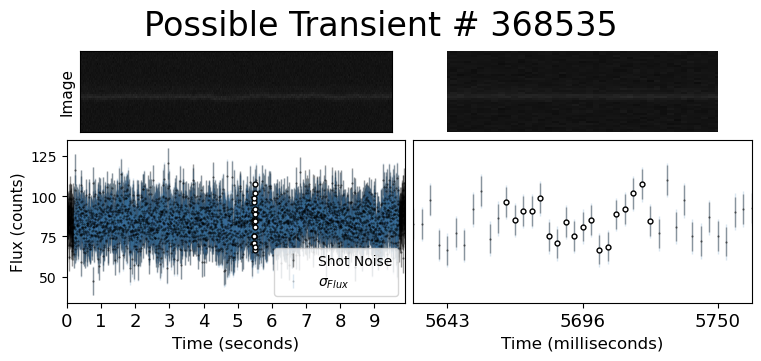

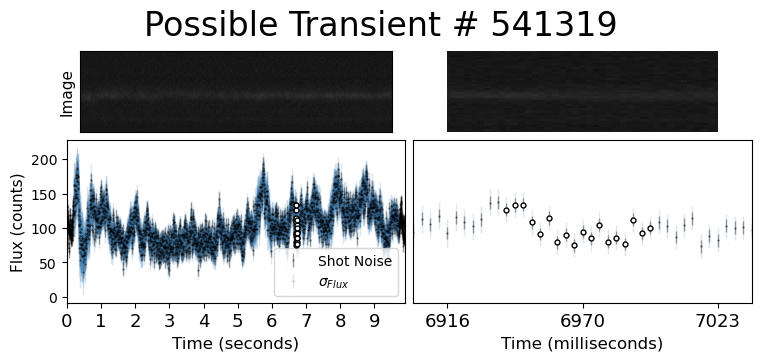

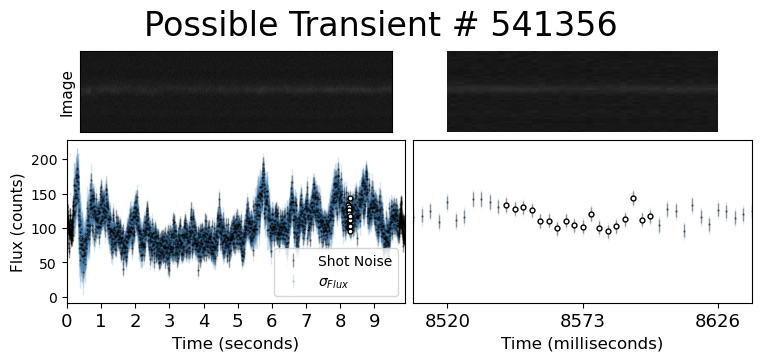

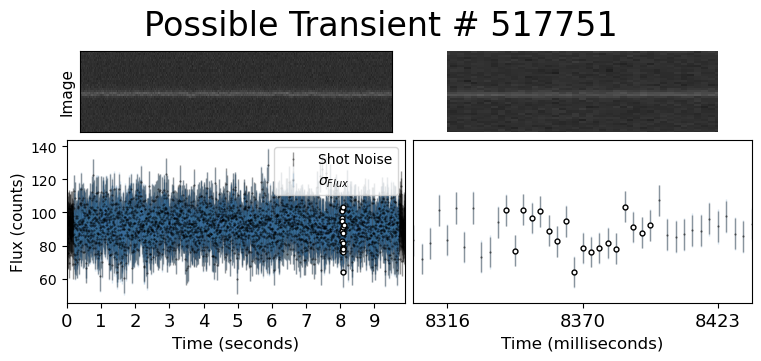

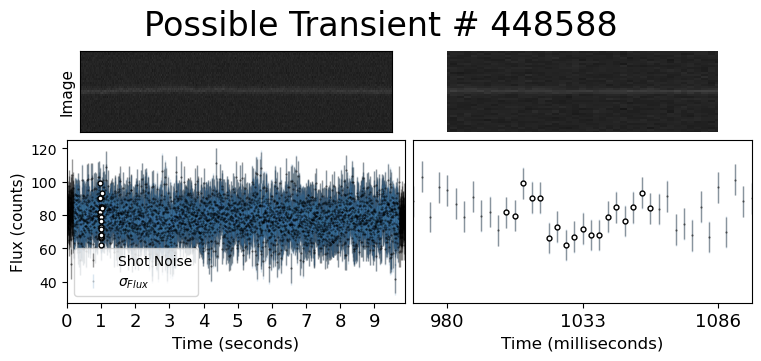

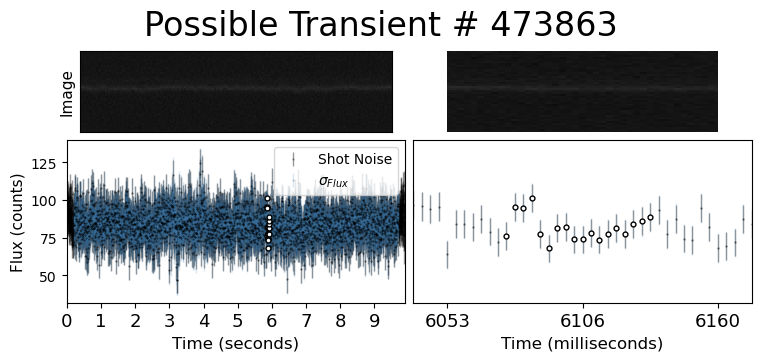

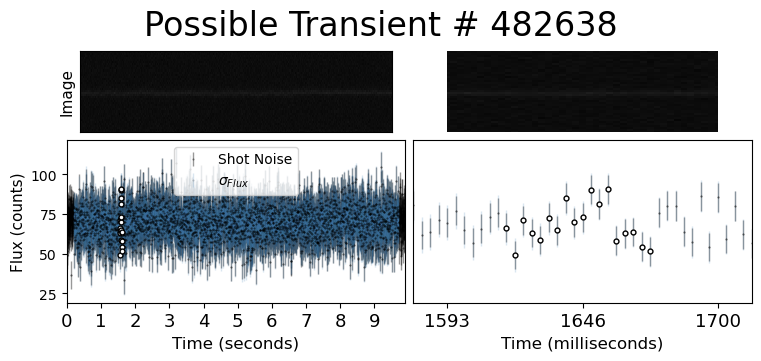

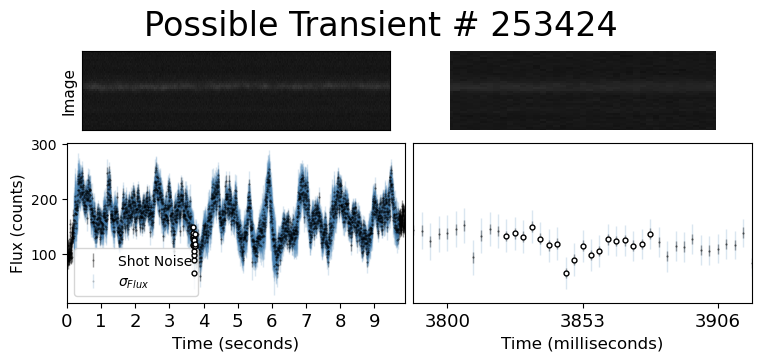

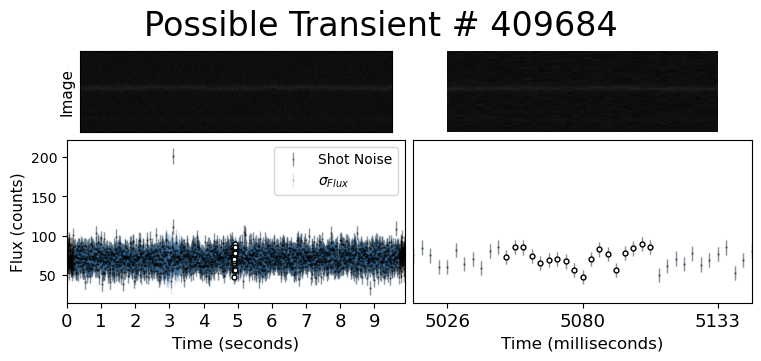

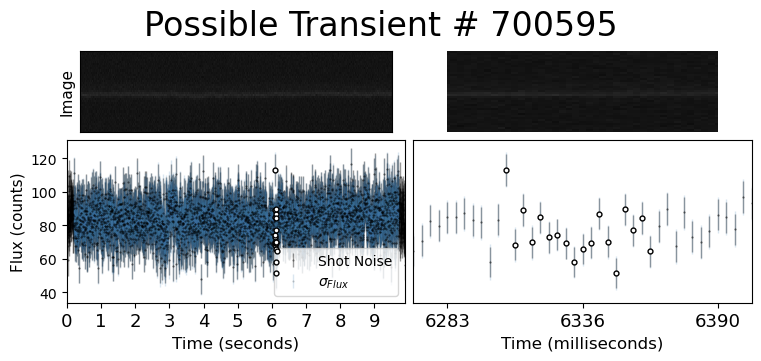

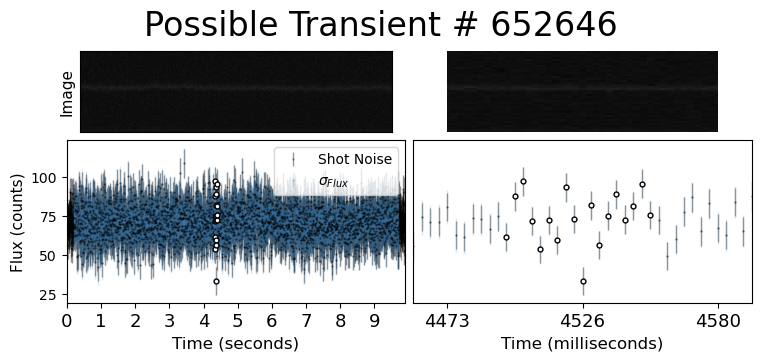

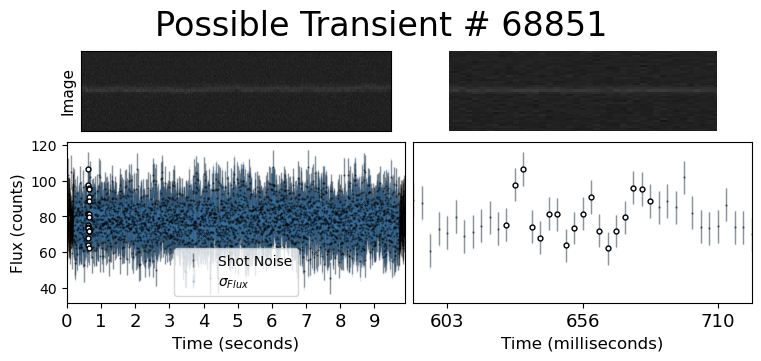

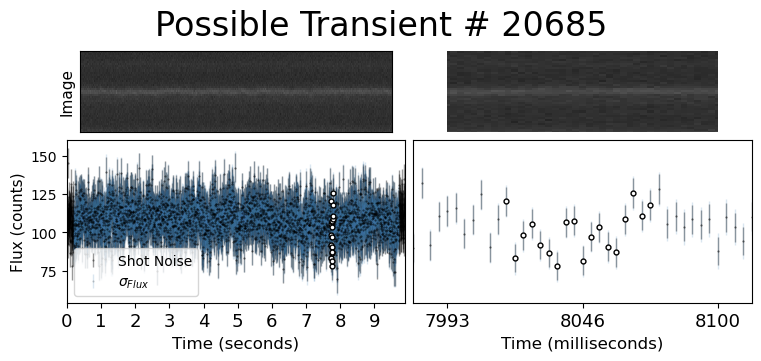

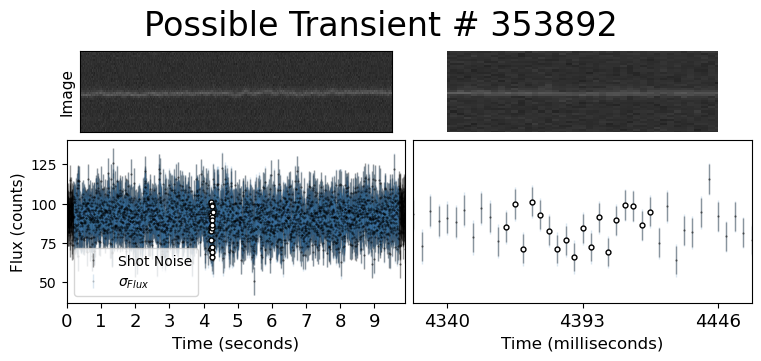

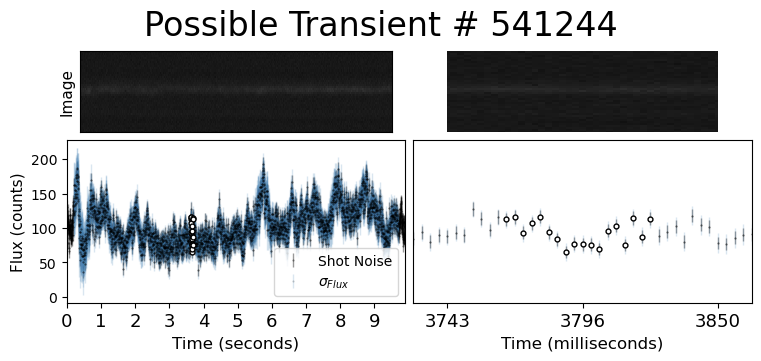

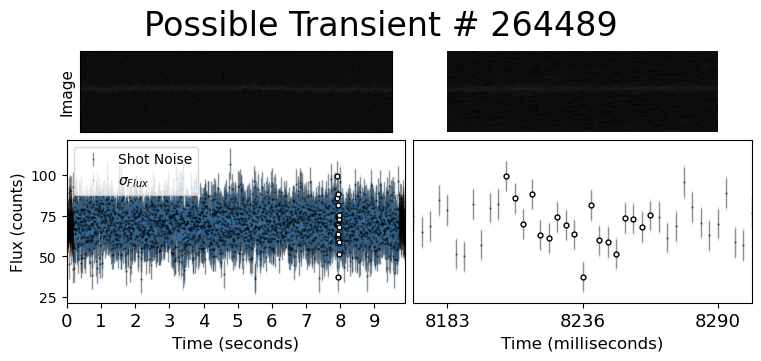

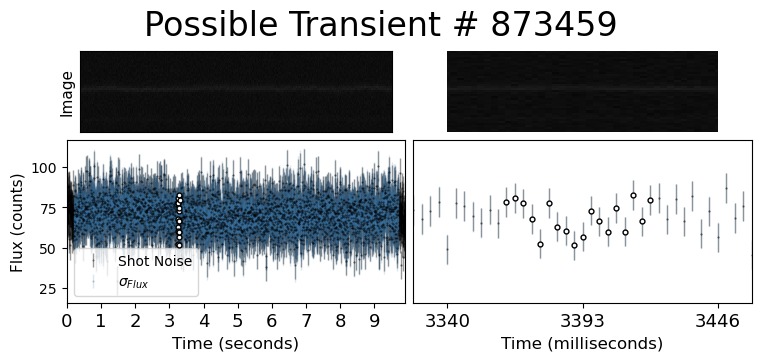

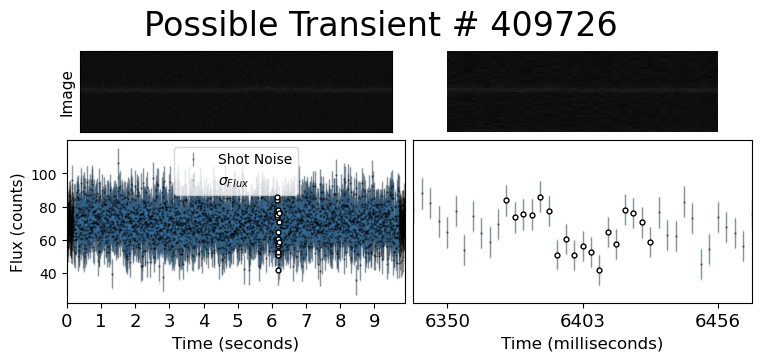

In [19]:
for index in some_indices:
    rff.plot_time_series_again_aperture(df_l3, index)

In [20]:
df_l3.loc[some_indices]

,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,quad,...,signal_local_new,sobel_ratio,sobels_x,sobels_y,stamp,norm_stamp,sobel_norm_stdv_rat,sobel_norm_diffmax,an_index,quadrant
464931,464931,464931,464931,464931,464931,464931,464931,1,ztf_20221020294271_000449_zr_c13_x_0029.,1,...,5.748404,3.271389,[[ 4.36004639e+00 1.55708618e+01 1.27270660e...,[[ 10.689331 12.343811 -11.290573 -9.5...,[[143.2823 142.5405 148.59322 150.21266 142....,[[0.13610494 0.13434286 0.14872044 0.15256727 ...,2.998091,3.271389,464931,1
368535,368535,368535,368535,368535,368535,368535,368535,54,ztf_20221020297847_000449_zr_c16_x_0022.,1,...,7.311468,3.588222,[[ 6.36495972e+00 2.58180237e+00 -1.02458649e...,[[-15.956696 -4.620407 -5.4877777 -12.6...,[[190.42851 190.64418 189.61546 189.75806 192....,[[0.04703345 0.04732543 0.04593271 0.04612576 ...,2.993776,3.588223,368535,1
541319,541319,541319,541319,541319,541319,541319,541319,263,ztf_20221020148032_000686_zg_c07_x_0020.,1,...,10.252383,3.030176,[[ 6.63059998e+00 -1.20004578e+01 8.04243469e...,[[-12.272842 -10.279846 2.877121 12.0...,[[168.11014 170.20523 164.17433 169.86229 176....,[[0.0503401 0.0526488 0.04600302 0.05227089 ...,2.982117,3.030176,541319,1
541356,541356,541356,541356,541356,541356,541356,541356,300,ztf_20221020148032_000686_zg_c07_x_0020.,1,...,27.324724,2.691076,[[ 2.08200073e+00 -4.15614319e+00 -5.47851562e...,[[ 2.61441040e+00 1.18977509e+01 9.97183228e...,[[168.16058 167.35512 166.12668 167.46184 167....,[[0.05039569 0.0495081 0.04815442 0.0496257 ...,2.967605,2.691076,541356,1
517751,517751,517751,517751,517751,517751,517751,517751,7,ztf_20221020297847_000449_zr_c01_x_0018.,1,...,4.685675,2.998953,[[ 8.84674072e-01 1.20222473e+01 1.69319153e...,[[ -7.028473 -18.024628 -21.308151 -2.8...,[[168.38118 169.52472 173.21341 168.94223 163....,[[0.14106128 0.14475138 0.15665445 0.14287174 ...,2.959018,2.998953,517751,1
448588,448588,448588,448588,448588,448588,448588,448588,1,ztf_20221020294271_000449_zr_c01_x_0012.,1,...,7.996373,3.178594,[[-4.83871460e-01 1.71666870e+01 3.46337891e...,[[-29.6353 -14.608368 -10.674957 -9.3...,[[173.76233 171.57805 176.36058 173.15396 168....,[[0.10167713 0.09708541 0.10713909 0.10039824 ...,2.947003,3.178594,448588,1
473863,473863,473863,473863,473863,473863,473863,473863,37,ztf_20221020297847_000449_zr_c16_x_0001.,1,...,7.479176,3.567036,[[ -2.667389 -1.0670319 -7.774063 -...,[[-8.32064819e+00 4.19895935e+00 4.89540100e...,[[191.55199 188.83304 190.20743 187.79321 187....,[[0.04927438 0.04570659 0.04751005 0.04434213 ...,2.936734,3.567037,473863,1
482638,482638,482638,482638,482638,482638,482638,482638,38,ztf_20221020294271_000449_zr_c12_x_0027.,4,...,8.373355,3.642476,[[-1.43328247e+01 4.94130859e+01 2.21692810e...,[[ 4.53167725e+00 -1.54208984e+01 -1.74875183e...,[[199.54224 198.02748 214.8152 201.16676 195....,[[0.02448068 0.0230325 0.03908243 0.02603381 ...,2.936105,3.642478,482638,4
253424,253424,253424,253424,253424,253424,253424,253424,85,ztf_20221020148032_000686_zg_c07_x_0012.,1,...,87.920980,3.423048,[[ -11.64389 -27.265015 -40.489624 ...,[[-2.35019226e+01 -1.46476440e+01 8.30877686e...,[[180.8566 177.7155 172.0569 163.83743 172....,[[0.06204185 0.05870598 0.05269651 0.04396738 ...,2.908402,3.423047,253424,1
409684,409684,409684,409684,409684,409684,409684,409684,301,ztf_20221020297847_000449_zr_c12_x_0016.,4,...,9.114065,3.158109,[[-2.72189484e+01 -3.89073334e+01 1.77276154e...,[[ 6.9010468 21.226059 20.905533 8.2...,[[207.36646 198.23663 196.38345 204.00484 202....,[[0.03706614 0.02777965 0.02589468 0.03364684 ...,2.901141,3.158108,409684,4


In [21]:
df_l3.loc[some_indices]['Diff']

464931    3.0
368535    3.0
541319    3.0
541356    0.0
517751    1.0
448588    1.0
473863    2.0
482638    3.0
253424    2.0
409684    2.0
700595    2.0
652646    2.0
68851     0.0
20685     2.0
353892    2.0
541244    0.0
264489    0.0
873459    1.0
409726    1.0
Name: Diff, dtype: float64

In [27]:
print("info about low SNR stars that trigger the cosmic ray criterion")
print('filename, quadrant, star x position, star y position')
for index in some_indices:
    print(df_l3.loc[index, 'filename'][:-6], df_l3.loc[index, 'quad'], df_l3.loc[index, 'closest_x'], df_l3.loc[index, 'closest_y'])

info about low SNR stars that trigger the cosmic ray criterion
filename, quadrant, star x position, star y position
ztf_20221020294271_000449_zr_c13_x 1 1769.0 1292.0
ztf_20221020297847_000449_zr_c16_x 1 1725.0 475.0
ztf_20221020148032_000686_zg_c07_x 1 1726.0 100.0
ztf_20221020148032_000686_zg_c07_x 1 1726.0 100.0
ztf_20221020297847_000449_zr_c01_x 1 1548.0 2113.0
ztf_20221020294271_000449_zr_c01_x 1 2636.0 2102.0
ztf_20221020297847_000449_zr_c16_x 1 1725.0 475.0
ztf_20221020294271_000449_zr_c12_x 4 2627.0 1200.0
ztf_20221020148032_000686_zg_c07_x 1 1726.0 100.0
ztf_20221020297847_000449_zr_c12_x 4 2780.0 155.0
ztf_20221020294271_000449_zr_c16_x 1 1724.0 478.0
ztf_20221020297847_000449_zr_c12_x 4 2629.0 1202.0
ztf_20221020294271_000449_zr_c01_x 1 2636.0 2102.0
ztf_20221020163819_000640_zg_c03_x 3 2775.0 2066.0
ztf_20221020297847_000449_zr_c01_x 1 1548.0 2113.0
ztf_20221020148032_000686_zg_c07_x 1 1726.0 100.0
ztf_20221020294271_000449_zr_c12_x 4 2627.0 1200.0
ztf_20221020294271_000449

In [33]:
newdf = df_l3.loc[some_indices]

In [35]:
for i, df_row in newdf.iterrows():
    print('lightcurve_'+df_row['filename'][:-1]+'_'+str(df_row['quad'])+'_'+f'{int(df_row["closest_x"]):04}'+'_'+f'{int(df_row["closest_y"]):04}'+'.csv')

lightcurve_ztf_20221020294271_000449_zr_c13_x_0029_1_1769_1292.csv
lightcurve_ztf_20221020297847_000449_zr_c16_x_0022_1_1725_0475.csv
lightcurve_ztf_20221020148032_000686_zg_c07_x_0020_1_1726_0100.csv
lightcurve_ztf_20221020148032_000686_zg_c07_x_0020_1_1726_0100.csv
lightcurve_ztf_20221020297847_000449_zr_c01_x_0018_1_1548_2113.csv
lightcurve_ztf_20221020294271_000449_zr_c01_x_0012_1_2636_2102.csv
lightcurve_ztf_20221020297847_000449_zr_c16_x_0001_1_1725_0475.csv
lightcurve_ztf_20221020294271_000449_zr_c12_x_0027_4_2627_1200.csv
lightcurve_ztf_20221020148032_000686_zg_c07_x_0012_1_1726_0100.csv
lightcurve_ztf_20221020297847_000449_zr_c12_x_0016_4_2780_0155.csv
lightcurve_ztf_20221020294271_000449_zr_c16_x_0020_1_1724_0478.csv
lightcurve_ztf_20221020297847_000449_zr_c12_x_0021_4_2629_1202.csv
lightcurve_ztf_20221020294271_000449_zr_c01_x_0016_1_2636_2102.csv
lightcurve_ztf_20221020163819_000640_zg_c03_x_0003_3_2775_2066.csv
lightcurve_ztf_20221020297847_000449_zr_c01_x_0026_1_1548_2113